---
title: "Bischoff's generalised modulus: measuring how narrow the narrow band is"
description: "One modulus built from the rate integral collapses the effectiveness-factor curves of every reaction order onto nearly one curve. Bischoff said the spread is 'about 15%' for orders one-half to three and 'about 30%' with zero order; this page root-finds both numbers (14.6% and 40.6% max/min, 28.9% as a fraction of the upper curve), finds the printed n = 1/2 reduction is a misprint his own 15% figure shows Figure 1 never used, and audits the construction out of sample on a finite cylinder, where a 1998 'arbitrary kinetics, < 1.5%' competitor misses six-fold while the 1965 collapse, combined with the shape's own curve, stays inside its advertised band."
categories: [sec:B, struct:S3, tier:T0, data:tier6, phase:gas-solid]
date: 2026-08-08
---

# Bischoff's generalised modulus: measuring how narrow the narrow band is

**Catalog ID:** `B1.3` · **Structure:** `S3` (1D steady BVP) · **Tier:** T0

Thiele's modulus makes the effectiveness factor of a first-order pellet a
single curve. Every other rate form gets its own curve, and
Langmuir-Hinshelwood kinetics get a *family* of them, which, as Bischoff
(1965) opens by observing, "greatly complicates practical computations."

His fix is one line: build the modulus from the integral of the rate, and the
large-$m$ ends of *all* the curves coincide exactly. What remains is the
intermediate range, about which the paper makes a quantitative claim: "the
spread is only about 15% for the most interesting cases of one-half- to
third-order reactions and is about 30% when zero-order reactions are
included." This page measures that claim (the collapse, its width, where the
width peaks) and what the same modulus does for adsorption kinetics, variable
diffusivity, and a shape it was never fitted to.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "B1.3-bischoff-generalised-modulus"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import csv
import functools
import warnings

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.integrate import IntegrationWarning, quad
from scipy.optimize import brentq, minimize_scalar
from pymrm.checks import observed_orders
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (Power, LHHW, VolChange, mb_eta, Curve, ZeroOrder,  # this page's model.py
                   mstar_power, K45SQ, m_eta_n1, m_eta_n2, m_eta_n3, m_eta_nhalf, m_eq20,
                   Slab, Cyl2D, mu1_series, mu2_eq30, eta_series_1st, pz_coeffs, eta_pz,
                   eq33, eq34)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
# QUADPACK reports round-off-limited refinement at the tolerances Route B asks
# for; Route B's accuracy is measured against the closed forms below, and the
# warning text embeds a temporary path that differs between runs
warnings.filterwarnings("ignore", category=IntegrationWarning)
claims = Claims(PAGE.split("-")[0])
BREAK = []


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught


def maximise(fun, lo, hi, ngrid=40, refine=True, edge_ok=False):
    """Largest value of ``fun`` on ``[lo, hi]``: a log-spaced scan, then Brent's
    method in ``log x`` around the best scan point. Refuses a window-edge maximum
    unless ``edge_ok``, which returns the edge value (the break table uses it).
    ``refine=False`` returns the best scan point."""
    xx = np.geomspace(lo, hi, ngrid)
    vals = [fun(x) for x in xx]
    i = int(np.argmax(vals))
    if not refine or (edge_ok and i in (0, ngrid - 1)):
        return float(xx[i]), float(vals[i])
    assert 0 < i < ngrid - 1, "maximum at the window edge: widen the window"
    lo_x, mid_x, hi_x = np.log(xx[i - 1]), np.log(xx[i]), np.log(xx[i + 1])
    try:
        res = minimize_scalar(lambda lx: -fun(np.exp(lx)), bracket=(lo_x, mid_x, hi_x),
                              method="brent", options={"xtol": 1e-11})
    except ValueError:     # a flat top ties the scan values: no valid bracket
        res = minimize_scalar(lambda lx: -fun(np.exp(lx)), bounds=(lo_x, hi_x),
                              method="bounded", options={"xatol": 1e-11})
    return float(np.exp(res.x)), float(-res.fun)

## Background

Bischoff's own account of the lineage, from p. 351: "Thiele (2) and Zeldovich
(3) in 1939 gave the early, and now classical, treatments." Thiele's modulus
for a first-order reaction is $m = L\sqrt{k_v/D}$, a grouping of rate
coefficient, diffusivity and half-width; each reaction order needs its own
version, and Chu and Hougen's adsorption-rate curves (his ref. 7) need a fresh
curve for every parameter pair $(\zeta, C_o)$. The paper's purpose, in its own
words: "it can be stated that a general solution would be very desirable. The
purpose of this work is to show how this can be approximately realized."

The mathematics is a slab (equivalently a single pore): steady diffusion with
an arbitrary rate form $r(C)$ and concentration-dependent diffusivity $D(C)$,

$$\frac{\mathrm{d}}{\mathrm{d}x}\!\left[D(C)\,\frac{\mathrm{d}C}{\mathrm{d}x}\right] = r(C),
\qquad C(0) = C_o,\qquad \frac{\mathrm{d}C(L)}{\mathrm{d}x} = 0,$$

his eqs. (1)-(3), with $x=0$ the surface and $x=L$ the sealed centre. A first
integral (his eq. 5) gives the flux in terms of $\int D\,r\,\mathrm{d}C$, and
everything on this page follows from that.

**Why this page completes a quartet.** [`B1.1`](../B1.1-thiele-weisz-hicks/)
is Thiele's curve itself; [`B1.2`](../B1.2-aris-shape-factor/) is Aris's
collapse across *shapes* at fixed (first-order) kinetics, using the
volume-to-surface length $v_p/s_x$; this page is the collapse across
*kinetics* at fixed shape. Bischoff cites exactly that division of labour: for
other geometries, "Aris (8) has shown that by choosing appropriate
characteristic lengths, other geometrical shapes give approximately similar
results." The final section combines the two collapses on a shape and a rate
form neither paper computed, and audits a 1998 competitor, Pan & Zhu's
approximate effectiveness factor for arbitrary kinetics in a cylinder, on the
same problem.

## The published model

**The general asymptotic solution and the modulus.** For a semi-infinite slab
(large modulus) the surface flux is exact and explicit (his eq. 11), and
Bischoff defines the general modulus so that the asymptote is
$\mathcal{E} = 1/m$ for *every* rate form (his eq. 13):

$$m \;\equiv\; \frac{L\,r(C_o)}{\sqrt{2}}
\left[\int_0^{C_o} D(\alpha)\,r(\alpha)\,\mathrm{d}\alpha\right]^{-1/2}.$$

For the finite slab the exact solution is parametric in the (unknown) centre
concentration $C_L$: his eq. (14) gives $m$ (one printed exponent of which is
a misprint, one of five printed defects reported in the Results) and his
eq. (15) gives

$$\mathcal{E} \;=\; \frac{1}{m}\left[\frac{\int_{C_L}^{C_o} D\,r\,\mathrm{d}C}
{\int_{0}^{C_o} D\,r\,\mathrm{d}C}\right]^{1/2}.$$

**Simple orders, $r = k_v C^n$** (his eq. 16). The modulus reduces to
$m = L\sqrt{(n+1)\,k_v C_o^{\,n-1}/(2D)}$ (eq. 17), the standard modulus
times $\sqrt{(n+1)/2}$, and eq. (15) reduces to
$\mathcal{E} = (1/m)\sqrt{1-(C_L/C_o)^{n+1}}$ (eq. 19) with $m(C_L)$ from the
quadrature of eq. (20). The paper evaluates five orders:

| $n$ | printed solution | eqs. |
|---|---|---|
| 1 | $\mathcal{E} = \tanh m/m$ | 21 |
| 0 | $\mathcal{E} = 1$ for $m<1$, $1/m$ for $m>1$ (attributed to Wheeler, his ref. 4) | 22 |
| 2 | incomplete elliptic integral $F(\phi,k)$, $k=\sin 15°$ | 23-24 |
| 3 | $F(\phi,k)$, $k = \sin 45°$ | 25-26 |
| 1/2 | $F$ and $E$, $k=\sin 15°$ | 27-28 |

and states the claim this page measures: **"the spread is only about 15% for
the most interesting cases of one-half- to third-order reactions and is about
30% when zero-order reactions are included"** (p. 354), restated in the
summary as "if reactions of order less than one-half are excluded, the spread
between all the various curves is about 15%."

**Adsorption (LHHW) kinetics**, $r = k_v C/(\zeta + C)$, the form Chu & Hougen
computed curve families for. The general modulus becomes (his eqs. 29/31)

$$m = \frac{M}{\sqrt 2}\,\frac{C_o}{\zeta + C_o}
\left[C_o - \zeta\ln\!\left(1+\frac{C_o}{\zeta}\right)\right]^{-1/2},
\qquad M = L\sqrt{k_v/D},$$

with $M$ the standard modulus of Chu and Hougen. The paper does not recompute
their curves ("this paper will directly use their curves, which are redrawn
in Figure 2") and replots them against $m$ as its Figure 3, concluding "the
spread is again about the same as for the simple order reactions." Here the
curves are computed, not redrawn, so that sentence too becomes a number.

**First-order reaction with volume change**, $D(C) = D/(\omega C + 1)$
(eq. 32): the modulus correction is closed-form (eq. 33),
$m = M\,|\omega C_o|\,[\,\omega C_o - \ln(\omega C_o + 1)]^{-1/2}/\sqrt 2$,
and Table 1, the paper's only table, compares it at four values of
$\omega C_o$ with Hawthorn's empirical correction
$M\,[\omega C_o/\ln(1+\omega C_o)]^{0.7}$ (eq. 34).

**What the paper does *not* print:** any measurement. Every number in it is
computed from the model, so this is a provenance tier 6 page throughout, and
"agreement" below means agreement between independent computations: Bischoff's
printed ones, closed forms, quadrature of his parametric solution, and pymrm
finite-volume solutions of the underlying BVP.

## Parameters and assumptions

**Assumptions, all Bischoff's:** steady state; a single reaction with rate a
function of one concentration; isothermal; slab geometry (or a single pore),
with surface concentration held at $C_o$ and zero flux at the centre;
diffusivity constant or a known function $D(C)$. Nonisothermal pellets, film
resistance and bimodal pore structures are explicitly deferred by the paper to
its refs. 1, 4-6 and are not treated here (the nonisothermal pellet is
[`B1.1`](../B1.1-thiele-weisz-hicks/)'s second half).

**Everything is dimensionless.** With $c = C/C_o$, rates normalised so
$\tilde r(1) = 1$ and $\tilde d = D(C)/D$, the model has no physical
parameters at all, only the rate-form shape ($n$, or $\zeta^* = \zeta/C_o$,
or $\omega C_o$) and the modulus. The normalisation shows a reduction:
Chu & Hougen's two-parameter family $(\zeta, C_o)$ is the one-parameter family
$\zeta^* = \zeta/C_o$; Bischoff's Figures 2a-c vary $C_o$ and $\zeta$
separately because both are dimensional there.

**How the sources were read.** Both PDFs are CCITT-G4 bilevel scans
(Bischoff at 300 ppi native, Pan & Zhu at 600 ppi, checked with
`pdfimages -list`; rendering higher only interpolates). The Bischoff text
layer is poor (sub- and superscripts unreliable), so every equation, exponent
and table cell used here was read from a digit-scale crop of a
native-resolution render, and the three printed tables used are transcribed
into `data/` with provenance sidecars. Five printed defects were found this
way and are reported, never repaired silently, in the Results: one Table 1
cell, the $n = 1/2$ elliptic reduction and an exponent in eq. (14) (Bischoff),
plus one Table 5 cell and a sign in eq. (36) (the secondary source).

In [3]:
# The families and grids the page evaluates; there is no physical parameter.
KEYS_15 = (0.5, 1.0, 2.0, 3.0)      # "one-half- to third-order reactions"
KEYS_30 = (0.0,) + KEYS_15          # "... when zero-order reactions are included"
# zeta* = zeta/C_o of Bischoff's Figures 2a-c: zeta from 0.001 to 100 at C_o = 0.1, 0.5, 1
ZSTARS = sorted({round(z / co, 12) for z in (0.001, 0.01, 0.1, 1.0, 10.0, 100.0)
                 for co in (0.1, 0.5, 1.0)})
W_FAM = (0.4, 1.0, -0.5, -0.25)     # omega*C_o of Bischoff's Table 1
U_GRID = np.array([0.02, 0.05, 0.1, 0.2, 0.3, 0.366, 0.5, 0.7, 0.9, 0.99])  # C_L/C_o
N_SLAB = 400                        # cells of the pymrm slab (Route A)
N_CYL = 100                         # radial cells of the 2-D cylinder (Z = 1: 100 x 100)

## The data

Three small printed tables, all of them the authors' own computed values:
**nothing on this page is a measurement** (provenance tier 6; neither paper
reports an experiment relevant here).

- `bischoff-table1.csv`: Bischoff's Table 1 (modulus correction factors for
  volume change), all eight cells as printed.
- `pan-zhu-table5.csv`, `pan-zhu-table6.csv`: the secondary source's shape
  coefficients and its first-order accuracy test (columns $Z$ = 1 and 2),
  as printed.

One table is borrowed: [`B1.1`](../B1.1-thiele-weisz-hicks/)'s
`isothermal-exact.csv`, whose slab rows are $\tanh\phi/\phi$. That page flags
nothing about those rows (its caveats concern the non-isothermal continuation,
which is not used here). Its $\phi$ column is stored rounded, to at most
seven decimal places, which matters for the reconciliation at the end of the
Results.

The exact $\eta(m)$ curves computed below are exported as
`eta-generalised-modulus.csv` for reuse.

In [4]:
tab1 = load_data("bischoff-table1.csv", page=PAGE)
pan5 = load_data("pan-zhu-table5.csv", page=PAGE)
pan6 = load_data("pan-zhu-table6.csv", page=PAGE)
print(cite_data(load_meta("bischoff-table1.csv", page=PAGE)))
print(cite_data(load_meta("pan-zhu-table6.csv", page=PAGE)))
print(f"{len(tab1)} Table 1 rows; {len(pan5)} Table 5 Z-values; {len(pan6)} Table 6 rows "
      f"across Z = {[float(z) for z in sorted(pan6['Z'].unique())]}")

Bischoff, K. B. (1965) — AIChE Journal 11(2) 351-355 — doi:10.1002/aic.690110229 — transcribed
Pan, T.; Zhu, B. (1998) — Chemical Engineering Science 53(5) 933-946 — doi:10.1016/S0009-2509(97)00385-0 — transcribed
4 Table 1 rows; 9 Table 5 Z-values; 18 Table 6 rows across Z = [1.0, 2.0]


## PyMRM implementation

Three routes to $\eta(m)$, sharing no assembly. The model code is in
`model.py`.

**Route A: pymrm finite volume (`Slab`).** The BVP itself,
$\mathrm{d}[\tilde d(c)\,c']/\mathrm{d}x = \Phi^2\tilde r(c)$ on $x\in(0,1)$,
with $x = 0$ the centre and $x = 1$ the surface. The boundary dictionaries use
the outward normal: `{"a": 1, "b": 0, "d": 0}` at $x = 0$ is $c'(0) = 0$
(symmetry), `{"a": 0, "b": 1, "d": 1}` at $x = 1$ is $c(1) = 1$.
`construct_grad` and `construct_div` (`nu=0`, a slab) are assembled once.
With constant diffusivity the residual is that constant operator plus the
reaction, whose Jacobian is `NumJac((n, 1))` (one field: `(n, 1)`, never
`(n,)`). With $\tilde d(c)$ the face diffusivity depends on the state, so
the whole residual, $\mathrm{div}(-\tilde d(c_f)\,\mathrm{grad}\,c) +
\Phi^2\tilde r(c)$, goes to one `NumJac((n, 1), axes_diagonals=[0])`: the
residual of a cell reads its two neighbours through the face values $c_f$
(linear between cells by `interp_cntr_to_stagg`, at the two boundaries from
`compute_boundary_values`). Every solve is one `newton` call with
`tol=1e-12`, `stagnation=True` and `bounds=(0, inf)` ($c^n$ with $n < 1$ is
undefined below zero), and raises unless newton reports success. $\eta$ is
the volume average of the rate; the surface flux read with
`compute_boundary_values` is the same sum rearranged (the finite-volume
divergence telescopes to the boundary flux), so their gap is the solve
residual, checked as an identity and not counted as a second route.

**Route B: quadrature of Bischoff's parametric solution (`mb_eta`, `Curve`).**
Eqs. (14)-(15) with the *inner* integral $\int \tilde d\,\tilde r\,\mathrm{d}c$
in closed form for every rate form used (power law, LHHW, volume change), the
outer integral by adaptive quadrature after the substitution $c = C_L + s^2$
that removes the square-root singularity, and $C_L(m)$ by `brentq` in
$\mathrm{logit}(C_L/C_o)$, which resolves both ends of the curve. One
exponent of eq. (14) is amended in the process; that is a printed defect of
the source, reported with proof in its own Results section below.

**Route C: the paper's closed forms.** Eqs. (21)-(28): `tanh`, the Wheeler
piecewise form, and the incomplete elliptic integrals via
`scipy.special.ellipkinc`/`ellipeinc`, independent of Route B's quadrature.
One implementation detail matters: the printed $\sin\phi$ parametrisations
pass through $\phi = \pi/2$ (at $C_o/C_L = 1+\sqrt3$ for the $k=\sin15°$
pair), so $\phi$ is evaluated from the equivalent
$\cos\phi = (\sqrt3+1-t)/(\sqrt3-1+t)$, which carries the branch.

In [5]:
CURVES = {n: Curve(Power(n)) for n in KEYS_15}      # Route B, the exact curves
CURVES[0.0] = ZeroOrder()                           # eq. (22)
CLOSED = {0.5: m_eta_nhalf, 1.0: m_eta_n1, 2.0: m_eta_n2, 3.0: m_eta_n3}   # Route C
SLAB = Slab(N_SLAB)
print(f"slab: {SLAB.n} cells, unknowns shaped {SLAB.shape}; boundary conditions "
      f"{SLAB.bc[0]} at x = 0 (centre) and {SLAB.bc[1]} at x = 1 (surface)")

slab: 400 cells, unknowns shaped (400, 1); boundary conditions {'a': 1.0, 'b': 0.0, 'd': 0.0} at x = 0 (centre) and {'a': 0.0, 'b': 1.0, 'd': 1.0} at x = 1 (surface)


## Results

### The three routes agree before anything is measured

Route B (quadrature of eqs. 14-15) against Route C (the printed closed
forms), across the whole parametric range. A wrong elliptic modulus, a
dropped branch or a mistranscribed prefactor breaks this at once, and the
break table at the end injects exactly those defects. The $n=1/2$ column here
uses the **amended** reduction; the as-printed one has its own section.

In [6]:
def route_bc_dev(closed=CLOSED):
    """Worst relative gap between Route B and Route C over U_GRID, in m and eta."""
    dev = 0.0
    for n, f in closed.items():
        for u in U_GRID:
            m_b, e_b = mb_eta(Power(n), u)
            m_c, e_c = f(u)
            dev = max(dev, abs(m_b / m_c - 1), abs(e_b / e_c - 1))
    return dev


def eq20_dev(denominator_exponent=0.5):
    """Worst relative gap in m between eq. (20) and Route B."""
    return max(abs(m_eq20(n, u) / mb_eta(Power(n), u, denominator_exponent)[0] - 1)
               for n in KEYS_15 for u in (0.1, 0.5, 0.9))


def mstar_extrapolated(n=0.5, power=0.25):
    """Dead-zone onset from Route B: m(u) at u = 1e-8 and 1e-10, extrapolated
    to u = 0 assuming m - m* ~ u^power ((1 - n)/2 = 1/4 for n = 1/2)."""
    u1, u2 = 1e-8, 1e-10
    m1, m2 = mb_eta(Power(n), u1)[0], mb_eta(Power(n), u2)[0]
    return (m2 * u1 ** power - m1 * u2 ** power) / (u1 ** power - u2 ** power)


def asymptote_dev(m=30.0, standard_modulus=False):
    """Worst |eta m - 1| at m for n = 2 and 3 (n = 1 and below are 1/m there
    by construction: the n = 1 table ends at m = 23.7, n <= 1/2 dead-zones)."""
    dev = 0.0
    for n in (2.0, 3.0):
        m_n = m * np.sqrt((n + 1) / 2) if standard_modulus else m
        dev = max(dev, abs(CURVES[n].eta(m_n) * m - 1))
    return dev


claims.bound("routeB_vs_closed_forms_worst_rel", route_bc_dev(), max=1e-10, basis="tolerance",
             note="Route B's outer quadrature runs at epsrel 1e-10")
claims.bound("eq20_vs_routeB_worst_rel", eq20_dev(), max=1e-10, basis="tolerance",
             note="both are quadratures at epsrel 1e-10 or tighter")
claims.bound("mstar_nhalf_extrapolated_rel_dev",
             abs(mstar_extrapolated() / mstar_power(0.5) - 1), max=1e-10, basis="theory",
             note="two-point extrapolation removes the leading u^(1/4) term")
claims.value("asymptote_eta_m_dev_at_m30", asymptote_dev(), rtol=1e-3)
print(f"Route B against the closed forms, worst relative gap over {len(U_GRID)} centre "
      f"concentrations x {len(CLOSED)} orders: below 1e-10 "
      f"(here {claims['routeB_vs_closed_forms_worst_rel']:.0e})")
print(f"eq. (20) by quadrature against Route B, worst: below 1e-10 "
      f"(here {claims['eq20_vs_routeB_worst_rel']:.0e})")
print(f"n = 1/2 dead-zone onset: m* = (n+1)/(1-n) = {mstar_power(0.5):g}; Route B "
      f"extrapolated in u^(1/4) to within 1e-10 "
      f"(here {claims['mstar_nhalf_extrapolated_rel_dev']:.0e})")
print(f"|eta m - 1| at m = 30, worst of n = 2 and 3: "
      f"{claims['asymptote_eta_m_dev_at_m30']:.3e}")

Route B against the closed forms, worst relative gap over 10 centre concentrations x 4 orders: below 1e-10 (here 2e-12)
eq. (20) by quadrature against Route B, worst: below 1e-10 (here 3e-13)
n = 1/2 dead-zone onset: m* = (n+1)/(1-n) = 3; Route B extrapolated in u^(1/4) to within 1e-10 (here 5e-14)
|eta m - 1| at m = 30, worst of n = 2 and 3: 2.254e-05


**pymrm against Route B.** Eight rate forms (four orders, two LHHW, two volume
change) at three moduli each; $n = 1/2$ is taken on its smooth branch
($m < m^* = 3$), its dead zone in the next section. Every case is solved on
a ladder of 100 to 800 cells, so that the gap at 400 cells can be read as
grid error or not.

In [7]:
FORMS_A = [Power(0.5), Power(1), Power(2), Power(3),
           LHHW(0.1), LHHW(10.0), VolChange(1.0), VolChange(-0.5)]
CASES_A = [(rf, m) for rf in FORMS_A
           for m in ((0.3, 1.0, 2.5) if getattr(rf, "n", None) == 0.5 else (0.3, 1.0, 3.0))]
_ref_curves = {rf.label: Curve(rf) for rf in FORMS_A}
REF_A = np.array([_ref_curves[rf.label].eta(m) for rf, m in CASES_A])
LADDER_A = (100, 200, 400, 800)


def slab_errors(n, nu=0, read="volume", flux_read="face"):
    """|eta_pymrm/eta_routeB - 1| for every case on n cells; and the gap between
    the surface-flux (flux_read) and the volume-average eta of each solve."""
    slab, err, gap = Slab(n, nu), [], []
    for (rf, m), ref in zip(CASES_A, REF_A):
        Phi = m * np.sqrt(2.0 * rf.Rint(0.0, 1.0))
        c, _ = slab.solve(rf, Phi)
        e = slab.eta_of(c, rf, Phi, read)
        err.append(abs(e / ref - 1))
        gap.append(abs(slab.eta_of(c, rf, Phi, flux_read) - slab.eta_of(c, rf, Phi)))
    return np.array(err), np.array(gap)


def slab_ladder(**kw):
    errs = {n: slab_errors(n, **kw)[0] for n in LADDER_A}
    worst = np.array([errs[n].max() for n in LADDER_A])
    case_orders = np.log2(errs[400] / errs[800])
    return errs, worst, case_orders


ERR_A, WORST_A, ORD_A = slab_ladder()
FLUX_GAP = slab_errors(N_SLAB)[1].max()
claims.value("pymrm_slab_worst_rel", WORST_A[LADDER_A.index(N_SLAB)])
claims.bound("pymrm_slab_observed_order", np.log2(WORST_A[2] / WORST_A[3]), min=1.9, max=2.1,
             basis="theory", note="second-order finite volume; worst case of 24, 400 to 800 cells")
claims.bound("pymrm_slab_case_orders_min", ORD_A.min(), min=1.6, max=2.4, basis="chosen",
             note="per-case orders 400 to 800 cells; pre-asymptotic where two error terms compete")
claims.bound("pymrm_slab_case_orders_max", ORD_A.max(), min=1.6, max=2.4, basis="chosen",
             note="per-case orders 400 to 800 cells; pre-asymptotic where two error terms compete")
claims.bound("eta_flux_vs_volume_worst", FLUX_GAP, max=1e-8, basis="identity",
             note="finite-volume conservation; the gap is the residual of the solve")
print(f"{'cells':>6}{'worst |eta/eta_B - 1| over ' + str(len(CASES_A)) + ' cases':>40}")
for n, w in zip(LADDER_A, WORST_A):
    print(f"{n:6d}{w:40.3e}")
print(f"worst case, 400 -> 800 cells: order {claims['pymrm_slab_observed_order']:.2f}; per case "
      f"the orders range from {ORD_A.min():.2f} to {ORD_A.max():.2f}")
_slow = [f"{rf.label} at m = {m:g}" for (rf, m), o in zip(CASES_A, ORD_A) if abs(o - 2) > 0.1]
print(f"cases more than 0.1 from order 2 (pre-asymptotic): {len(_slow)} "
      f"({'; '.join(_slow) or 'none'})")
print(f"surface flux (compute_boundary_values) against the volume average, worst of "
      f"{len(CASES_A)} solves on {N_SLAB} cells: below 1e-8 (here {FLUX_GAP:.0e})")

 cells     worst |eta/eta_B - 1| over 24 cases
   100                               3.154e-05
   200                               7.917e-06
   400                               1.983e-06
   800                               4.963e-07
worst case, 400 -> 800 cells: order 2.00; per case the orders range from 1.73 to 2.21
cases more than 0.1 from order 2 (pre-asymptotic): 2 (n = 1 at m = 3; LHHW z* = 10 at m = 3)
surface flux (compute_boundary_values) against the volume average, worst of 24 solves on 400 cells: below 1e-8 (here 1e-10)


### The dead zone

For $n<1$ past $m^*$ the reactant vanishes on an interior region, and the
rate's square-root kink at $c=0$ sits on the free boundary. The exact answer
there is $\eta = 1/m$. The page solves it with the regularised rate
$r_\varepsilon = \sqrt{c+\varepsilon} - \sqrt{\varepsilon}$ and its exact
Jacobian (one `construct_coefficient_matrix` of
$\Phi^2/(2\sqrt{c+\varepsilon})$ on the diagonal), and treats $\varepsilon$
as an error axis: a ladder in $\varepsilon$ on every grid, extrapolated to
$\varepsilon \to 0$ with `observed_orders`, then a grid ladder of those
limits. The unregularised solve is shown beside it, as current pymrm handles
it.

In [8]:
DZ, M_DZ = Power(0.5), 5.0
PHI_DZ = M_DZ * np.sqrt(2.0 * DZ.Rint(0.0, 1.0))
EPS_LADDER = (1e-6, 1e-8, 1e-10, 1e-12, 1e-14, 1e-16)
DZ_NS = (100, 200, 400, 800)


def deadzone_eta(n, eps, nu=0, read="volume", **kw):
    """eta m - 1 of the regularised dead-zone solve, and whether it converged."""
    slab = Slab(n, nu)
    c, sol = slab.solve(DZ, PHI_DZ, eps=eps, check=False, **kw)
    return slab.eta_of(c, DZ, PHI_DZ, read) * M_DZ - 1, bool(sol.success)


def deadzone_study(rung=100.0, extrapolate=True, **kw):
    """eps ladder on every grid, its eps -> 0 limit, and the grid ladder of the limits.

    The extrapolation solves at eps = 1e-12, 1e-12/rung, 1e-12/rung^2 and reads
    them as a refinement by 100 per rung; the error is O(sqrt(eps))."""
    table, limits, eps_orders, n_ok = {}, {}, [], 0
    for n in DZ_NS:
        row = [deadzone_eta(n, eps, **kw) for eps in EPS_LADDER]
        n_ok += sum(ok for _, ok in row)
        table[n] = [v for v, _ in row]
        if extrapolate:
            lad = observed_orders(
                lambda q: deadzone_eta(n, 1e-12 * q ** -(np.log(rung) / np.log(100.0)), **kw)[0],
                (1, 100, 10000))
            limits[n], eps_orders = lad["extrapolated"], eps_orders + [lad["orders"][-1]]
        else:
            limits[n] = table[n][EPS_LADDER.index(1e-12)]
    grid = observed_orders(lambda n: limits[n], DZ_NS)
    return table, limits, eps_orders, grid, n_ok


DZ_TABLE, DZ_LIM, DZ_EPS_ORD, DZ_GRID, DZ_OK = deadzone_study()
print(f"n = 1/2, m = {M_DZ:g} (dead zone; exact eta m - 1 = 0): eta m - 1 of the regularised solve")
print(f"{'cells':>6}" + "".join(f"{f'eps = {e:.0e}':>13}" for e in EPS_LADDER) + f"{'eps -> 0':>13}")
for n in DZ_NS:
    print(f"{n:6d}" + "".join(f"{v:13.3e}" for v in DZ_TABLE[n]) + f"{DZ_LIM[n]:13.3e}")
claims.exact("deadzone_regularised_converged", DZ_OK)
claims.value("pymrm_deadzone_rel_dev", abs(DZ_TABLE[400][EPS_LADDER.index(1e-12)]))
claims.bound("deadzone_eps_order_min", min(DZ_EPS_ORD), min=0.45, max=0.55, basis="theory",
             note="r_eps - r is O(sqrt(eps)) near c = 0; eps ratio 100 per rung")
claims.bound("deadzone_eps_order_max", max(DZ_EPS_ORD), min=0.45, max=0.55, basis="theory",
             note="r_eps - r is O(sqrt(eps)) near c = 0; eps ratio 100 per rung")
claims.bound("deadzone_grid_order", DZ_GRID["orders"][-1], min=1.8, max=2.1, basis="chosen",
             note="second order, pre-asymptotic: the free boundary sits inside a cell")
claims.bound("deadzone_extrapolated_dev", abs(DZ_GRID["extrapolated"]), max=1e-7, basis="chosen",
             note="Richardson limit of the eps -> 0 limits on 100 to 800 cells against eta = 1/m")
print(f"converged: {DZ_OK} of {len(DZ_NS) * len(EPS_LADDER)} solves; eps orders "
      f"{min(DZ_EPS_ORD):.2f} to {max(DZ_EPS_ORD):.2f} (theory 1/2); grid orders of the "
      f"eps -> 0 limits {', '.join(f'{o:.2f}' for o in DZ_GRID['orders'])}; their "
      f"Richardson limit is within 1e-7 of eta = 1/m "
      f"(here {claims['deadzone_extrapolated_dev']:.0e})")

n = 1/2, m = 5 (dead zone; exact eta m - 1 = 0): eta m - 1 of the regularised solve
 cells  eps = 1e-06  eps = 1e-08  eps = 1e-10  eps = 1e-12  eps = 1e-14  eps = 1e-16     eps -> 0
   100    2.268e-03    2.559e-04    5.240e-05    3.185e-05    2.978e-05    2.957e-05    2.954e-05
   200    2.241e-03    2.330e-04    3.064e-05    1.030e-05    8.259e-06    8.054e-06    8.031e-06
   400    2.234e-03    2.267e-04    2.461e-05    4.347e-06    2.315e-06    2.112e-06    2.089e-06
   800    2.232e-03    2.250e-04    2.303e-05    2.785e-06    7.579e-07    5.549e-07    5.324e-07
converged: 24 of 24 solves; eps orders 0.50 to 0.50 (theory 1/2); grid orders of the eps -> 0 limits 1.86, 1.93; their Richardson limit is within 1e-7 of eta = 1/m (here 2e-08)


In [9]:
PLAIN = {"bounds=(0, inf)": {"bounds": (0.0, np.inf), "maxfev": 200},
         "damping='monotone', no bounds": {"bounds": None, "damping": "monotone", "maxfev": 200}}


def plain_runs(options, eps=0.0, exact_jacobian=True):
    """The dead-zone solve with the plain rate sqrt(max(c, 0)) (Jacobian by NumJac)
    on every grid: converged count, smallest of the last 50 steps over tol, the
    worst |eta m - 1| distance to the eps -> 0 limit of the same grid, and the
    largest over the grids of the smallest concentration."""
    n_ok, step_ratio, gap, c_min = 0, np.inf, 0.0, -np.inf
    tol = options.get("tol", 1e-12)
    for n in DZ_NS:
        slab = Slab(n)
        c, sol = slab.solve(DZ, PHI_DZ, eps=eps, check=False, exact_jacobian=exact_jacobian,
                            **options)
        n_ok += bool(sol.success)
        steps = [h["step_norm"] for h in sol.history[-50:]]
        step_ratio = min(step_ratio, min(steps) / tol)
        gap = max(gap, abs(slab.eta_of(c, DZ, PHI_DZ) * M_DZ - 1 - DZ_LIM[n]))
        c_min = max(c_min, float(c.min()))
    return n_ok, step_ratio, gap, c_min


PLAIN_RES = {k: plain_runs(v) for k, v in PLAIN.items()}
print(f"plain rate sqrt(max(c, 0)), newton tol=1e-12, stagnation=True, on {len(DZ_NS)} grids:")
for (k, (n_ok, ratio, gap, _)), name in zip(PLAIN_RES.items(),
                                         ("deadzone_plain_bounds_converged",
                                          "deadzone_plain_monotone_converged")):
    claims.exact(name, n_ok, margin=ratio, min_margin=10.0,
                 note="margin: smallest of the last 50 Newton steps over tol")
    print(f"  {k:<32} converged on {n_ok} of {len(DZ_NS)}; the last 50 steps stay at least "
          f"10 tol (here {ratio:.0f})")
claims.bound("deadzone_plain_eta_gap", max(r[2] for r in PLAIN_RES.values()), max=5e-6,
             basis="chosen", note="eta of the unconverged plain iterates against the eps -> 0 limit")
print(f"their eta m - 1 lies within 5e-6 of the regularised eps -> 0 limit of the same grid "
      f"(here {claims['deadzone_plain_eta_gap']:.0e})")
DEFAULT_TOL = 1.49012e-08                 # newton's default tol
PLAIN_DEFAULT = {**PLAIN["damping='monotone', no bounds"], "tol": DEFAULT_TOL}
_nd, _rd, _gd, _cd = plain_runs(PLAIN_DEFAULT)
claims.exact("deadzone_plain_default_tol_converged", _nd, margin=abs(np.log10(_rd)),
             min_margin=0.01, note="margin: |log10| of the smallest late step over tol")
claims.bound("deadzone_plain_default_tol_max_min_c", _cd, max=-1e-9, basis="chosen",
             note="largest over the grids of min c: every reported solution goes negative")
print(f"the same monotone solve at newton's default tol = {DEFAULT_TOL:g}: reports success on "
      f"{_nd} of {len(DZ_NS)} grids, by a thin margin (here the smallest late step is "
      f"{_rd:.2f} tol), on profiles that go negative in the dead zone (min c below -1e-9 on "
      f"every grid, here at most {_cd:.1e})")

plain rate sqrt(max(c, 0)), newton tol=1e-12, stagnation=True, on 4 grids:
  bounds=(0, inf)                  converged on 0 of 4; the last 50 steps stay at least 10 tol (here 12990)
  damping='monotone', no bounds    converged on 0 of 4; the last 50 steps stay at least 10 tol (here 134)
their eta m - 1 lies within 5e-6 of the regularised eps -> 0 limit of the same grid (here 1e-06)
the same monotone solve at newton's default tol = 1.49012e-08: reports success on 4 of 4 grids, by a thin margin (here the smallest late step is 0.53 tol), on profiles that go negative in the dead zone (min c below -1e-9 on every grid, here at most -3.6e-08)


In [10]:
_n_bounds = claims["deadzone_plain_bounds_converged"]
_n_monotone = claims["deadzone_plain_monotone_converged"]
display(Markdown(
    f"With the regularisation, every one of the {claims['deadzone_regularised_converged']} "
    f"solves converges (newton reports success), the error in $\\varepsilon$ falls as "
    f"$\\sqrt{{\\varepsilon}}$ on every grid (orders {min(DZ_EPS_ORD):.2f} to "
    f"{max(DZ_EPS_ORD):.2f}), and the $\\varepsilon \\to 0$ limits converge in the grid at "
    f"order {DZ_GRID['orders'][-1]:.2f} to within 1e-7 of the exact $\\eta = 1/m$ "
    f"(here {claims['deadzone_extrapolated_dev']:.0e}). At {N_SLAB} cells and $\\varepsilon = 10^{{-12}}$ the "
    f"deviation is {claims['pymrm_deadzone_rel_dev']:.1e}, about half grid error "
    f"({abs(DZ_LIM[400]):.1e} at $\\varepsilon \\to 0$) and half regularisation.\n\n"
    f"Without the regularisation, the same newton call does not converge on any of the "
    f"{len(DZ_NS)} grids: with `bounds=(0, inf)` it ends on the bound (converged "
    f"{_n_bounds} of {len(DZ_NS)}), and without bounds, with `damping='monotone'`, it "
    f"runs out of iterations (converged {_n_monotone} of {len(DZ_NS)}); in both, the "
    f"steps stay above "
    f"ten times the tolerance (`tol=1e-12`, `stagnation=True`). The unconverged iterates "
    f"are not far off: their $\\eta$ lies within 5e-6 of the regularised limit. At newton's "
    f"default `tol` ({DEFAULT_TOL:g}) the monotone solve reports success on "
    f"{claims['deadzone_plain_default_tol_converged']} of {len(DZ_NS)} grids, but the "
    f"reported profiles go negative in the dead zone, where the discrete solution is not, "
    f"and the smallest late step passes the test by a thin margin. No number on this page "
    f"rests on the unregularised solve."))

With the regularisation, every one of the 24 solves converges (newton reports success), the error in $\varepsilon$ falls as $\sqrt{\varepsilon}$ on every grid (orders 0.50 to 0.50), and the $\varepsilon \to 0$ limits converge in the grid at order 1.93 to within 1e-7 of the exact $\eta = 1/m$ (here 2e-08). At 400 cells and $\varepsilon = 10^{-12}$ the deviation is 4.3e-06, about half grid error (2.1e-06 at $\varepsilon \to 0$) and half regularisation.

Without the regularisation, the same newton call does not converge on any of the 4 grids: with `bounds=(0, inf)` it ends on the bound (converged 0 of 4), and without bounds, with `damping='monotone'`, it runs out of iterations (converged 0 of 4); in both, the steps stay above ten times the tolerance (`tol=1e-12`, `stagnation=True`). The unconverged iterates are not far off: their $\eta$ lies within 5e-6 of the regularised limit. At newton's default `tol` (1.49012e-08) the monotone solve reports success on 4 of 4 grids, but the reported profiles go negative in the dead zone, where the discrete solution is not, and the smallest late step passes the test by a thin margin. No number on this page rests on the unregularised solve.

### The collapse, and the width of the band

Five reaction orders on the generalised modulus. The spread at fixed $m$ is
reported two ways, because the paper does not say which it means:
$\eta_{\max}/\eta_{\min}-1$ (relative to the lowest curve) and
$(\eta_{\max}-\eta_{\min})/\eta_{\max}$ (as a fraction of the highest). The
extrema are **root-found, not sampled**: the smooth interior maximum by
Brent's method on the exact curves, and the kink candidates ($m = 1$, where
the $n=0$ curve breaks, and $m^* = 3$, where $n = 1/2$ enters its dead zone)
evaluated exactly.

In [11]:
def spread(m, keys, curves=CURVES):
    v = [curves[k].eta(m) for k in keys]
    return max(v) / min(v) - 1.0


def spread_frac(m, keys, curves=CURVES):
    v = [curves[k].eta(m) for k in keys]
    return (max(v) - min(v)) / max(v)


M_15, BAND_15 = maximise(lambda m: spread(m, KEYS_15), 0.2, 10.0)
BAND_15_FRAC = spread_frac(M_15, KEYS_15)
KINK_15 = max(spread(1.0, KEYS_15), spread(3.0, KEYS_15))
assert BAND_15 > KINK_15, "the interior maximum is the global one"
BAND_30 = spread(1.0, KEYS_30)                 # the kink of eq. (22)
BAND_30_FRAC = spread_frac(1.0, KEYS_30)
M_30, _ = maximise(lambda m: spread(m, KEYS_30), 0.2, 10.0)
ETA3_AT_1 = CURVES[3.0].eta(1.0)

claims.value("band_nhalf_to_3_max_relspread", BAND_15, rtol=1e-4)
claims.value("band_nhalf_to_3_argmax_m", M_15, rtol=1e-4)
claims.value("band_nhalf_to_3_frac_of_upper", BAND_15_FRAC, rtol=1e-4)
claims.value("band_incl_n0_at_kink_relspread", BAND_30, rtol=1e-4)
claims.value("band_incl_n0_frac_of_upper", BAND_30_FRAC, rtol=1e-4)
claims.value("band_incl_n0_argmax_m", M_30, rtol=1e-6)
claims.value("eta_n3_at_m1", ETA3_AT_1, rtol=1e-6)
print('Bischoff: "the spread is only about 15% for ... one-half- to third-order"')
print(f"  measured: {BAND_15:.2%} (max/min - 1) = {BAND_15_FRAC:.2%} (fraction of the upper "
      f"curve), at m = {M_15:.4f};")
print(f"  a root-found interior maximum, above both kink candidates (worst kink {KINK_15:.4f})")
print('Bischoff: "about 30% when zero-order reactions are included"')
print(f"  measured: {BAND_30:.2%} (max/min - 1) = {BAND_30_FRAC:.2%} (fraction of the upper "
      f"curve), at the kink of eq. (22),")
print(f"  m = 1 (the smooth search converges to m = {M_30:.6f}); the band there is "
      f"1 - eta_n3(1), eta_n3(1) = {ETA3_AT_1:.6f}")


# second route to the two headline numbers: the closed forms (Route C), extrema
# re-root-found
def spread_closed(m, with_zero, closed=CLOSED):
    def eta_c(f):
        u = brentq(lambda u: f(u)[0] - m, 1e-9, 1 - 1e-12, xtol=1e-14)
        return f(u)[1]
    vals = [eta_c(closed[n]) if m < {0.5: mstar_power(0.5)}.get(n, np.inf) else 1.0 / m
            for n in KEYS_15]
    if with_zero:
        vals.append(1.0 if m < 1.0 else 1.0 / m)
    return max(vals) / min(vals) - 1.0


def second_route(closed=CLOSED):
    m_c, band_c = maximise(lambda m: spread_closed(m, False, closed), 0.2, 10.0)
    band30_c = spread_closed(1.0, True, closed)
    return (max(abs(band_c / BAND_15 - 1), abs(band30_c / BAND_30 - 1)),
            abs(m_c / M_15 - 1), band_c, band30_c, m_c)


_sr = second_route()
claims.bound("band_second_route_gap", _sr[0], max=1e-9, basis="tolerance",
             note="relative gap of the two band values between Route B and Route C")
claims.bound("band_argmax_second_route_gap", _sr[1], max=1e-5, basis="tolerance",
             note="a flat maximum locates its abscissa only to about the square root "
                  "of the function's accuracy")
print(f"second route (closed forms, no shared quadrature): {_sr[2]:.6f} at m = {_sr[4]:.4f}; "
      f"with n = 0: {_sr[3]:.6f}")
print(f"relative gap of the band values: below 1e-9 (here {_sr[0]:.0e}); of the location "
      f"of the maximum: below 1e-5 (here {_sr[1]:.0e})")

Bischoff: "the spread is only about 15% for ... one-half- to third-order"
  measured: 14.61% (max/min - 1) = 12.75% (fraction of the upper curve), at m = 1.2702;
  a root-found interior maximum, above both kink candidates (worst kink 0.1342)
Bischoff: "about 30% when zero-order reactions are included"
  measured: 40.55% (max/min - 1) = 28.85% (fraction of the upper curve), at the kink of eq. (22),
  m = 1 (the smooth search converges to m = 1.000000); the band there is 1 - eta_n3(1), eta_n3(1) = 0.711476
second route (closed forms, no shared quadrature): 0.146091 at m = 1.2702; with n = 0: 0.405529
relative gap of the band values: below 1e-9 (here 1e-12); of the location of the maximum: below 1e-5 (here 2e-07)


In [12]:
# what the collapse replaced: the standard modulus M_n = L sqrt(k_v C_o^(n-1)/D),
# "a form of modulus similar to Equation (17), but with only the term C_o^(n-1)",
# so m = M_n ((n + 1)/2)^p with p = 1/2
def spread_std(M, keys, p=0.5):
    v = [CURVES[k].eta(M * ((k + 1.0) / 2.0) ** p) for k in keys]
    return max(v) / min(v) - 1.0


def std_asymptote(keys, p=0.5):
    """Large-M spread: every eta -> 1/m, so the ratio of the outer prefactors."""
    f = [((k + 1.0) / 2.0) ** p for k in keys]
    return max(f) / min(f) - 1.0


M_STD15, BAND_STD15 = maximise(lambda M: spread_std(M, KEYS_15), 0.2, 10.0)
M_STD30, BAND_STD30 = maximise(lambda M: spread_std(M, KEYS_30), 0.2, 10.0)
claims.value("std_modulus_band_nhalf_to_3", BAND_STD15, rtol=1e-4)
claims.value("std_modulus_band_incl_n0", BAND_STD30, rtol=1e-4)
claims.value("std_modulus_asympt_spread_nhalf_to_3", std_asymptote(KEYS_15), rtol=1e-9)
claims.value("std_modulus_asympt_spread_incl_n0", std_asymptote(KEYS_30), rtol=1e-9)
claims.value("std_modulus_spread_incl_n0_at_M1e3", spread_std(1e3, KEYS_30), rtol=1e-6)
print("the same five curves on the standard modulus M_n:")
print(f"  n in [1/2, 3]: largest spread {BAND_STD15:.1%} at M = {M_STD15:.3f} (on m: "
      f"{BAND_15:.1%}); at large M {std_asymptote(KEYS_15):.1%}, the ratio sqrt(4/1.5)")
print(f"  with n = 0   : largest spread {BAND_STD30:.1%} at M = {M_STD30:.3f} (on m: "
      f"{BAND_30:.1%}); at large M {std_asymptote(KEYS_30):.1%}, the ratio sqrt(4/1)")
print(f"  computed at M = 1000 with n = 0: {spread_std(1e3, KEYS_30):.6%}")
print(f"on m every large-m spread is zero by construction, which is all eq. (13) does; "
      f"the peak narrows by {BAND_STD15 / BAND_15:.1f}x and {BAND_STD30 / BAND_30:.1f}x")

the same five curves on the standard modulus M_n:
  n in [1/2, 3]: largest spread 68.2% at M = 2.091 (on m: 14.6%); at large M 63.3%, the ratio sqrt(4/1.5)
  with n = 0   : largest spread 120.6% at M = 1.414 (on m: 40.6%); at large M 100.0%, the ratio sqrt(4/1)
  computed at M = 1000 with n = 0: 100.000000%
on m every large-m spread is zero by construction, which is all eq. (13) does; the peak narrows by 4.7x and 3.0x


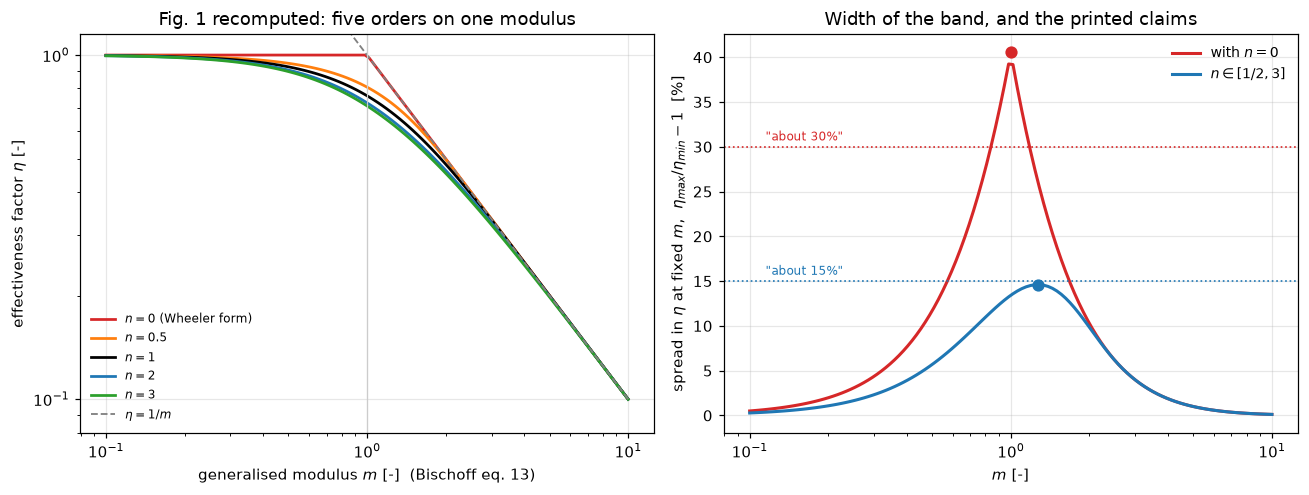

In [13]:
MM = np.geomspace(0.1, 10.0, 120)
ETA_TAB = {n: np.array([CURVES[n].eta(m) for m in MM]) for n in KEYS_30}
S15 = np.array([ETA_TAB[k] for k in KEYS_15]).max(0) / np.array([ETA_TAB[k] for k in KEYS_15]).min(0) - 1
S30 = np.array([ETA_TAB[k] for k in KEYS_30]).max(0) / np.array([ETA_TAB[k] for k in KEYS_30]).min(0) - 1

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.6))
ax = axes[0]
colors = {0.0: "tab:red", 0.5: "tab:orange", 1.0: "k", 2.0: "tab:blue", 3.0: "tab:green"}
for n in KEYS_30:
    ax.loglog(MM, ETA_TAB[n], color=colors[n], lw=1.8,
              label=f"$n = {n:g}$" + (" (Wheeler form)" if n == 0 else ""))
ax.loglog(MM, 1.0 / MM, "--", color="0.5", lw=1.2, label=r"$\eta = 1/m$")
ax.axvline(1.0, color="0.8", lw=0.8)
ax.set_xlabel(r"generalised modulus $m$ [-]  (Bischoff eq. 13)")
ax.set_ylabel(r"effectiveness factor $\eta$ [-]")
ax.set_ylim(0.08, 1.15)
ax.set_title("Fig. 1 recomputed: five orders on one modulus")
ax.legend(frameon=False, fontsize=8, loc="lower left")
ax = axes[1]
ax.semilogx(MM, 100 * S30, color="tab:red", lw=2.0, label="with $n=0$")
ax.semilogx(MM, 100 * S15, color="tab:blue", lw=2.0, label=r"$n \in [1/2, 3]$")
ax.axhline(15, color="tab:blue", ls=":", lw=1.1)
ax.axhline(30, color="tab:red", ls=":", lw=1.1)
ax.annotate('"about 15%"', (0.115, 15.7), fontsize=8, color="tab:blue")
ax.annotate('"about 30%"', (0.115, 30.7), fontsize=8, color="tab:red")
ax.plot([M_15], [100 * BAND_15], "o", color="tab:blue", ms=7)
ax.plot([1.0], [100 * BAND_30], "o", color="tab:red", ms=7)
ax.set_xlabel(r"$m$ [-]")
ax.set_ylabel(r"spread in $\eta$ at fixed $m$,  $\eta_{max}/\eta_{min}-1$  [%]")
ax.set_title("Width of the band, and the printed claims")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

In [14]:
display(Markdown(
    f"Both printed claims hold, each under one of the two natural readings, and the "
    f"page pins which: **{BAND_15:.2%} at $m = {M_15:.3f}$** for orders one-half to three "
    f"as $\\eta_{{\\max}}/\\eta_{{\\min}}-1$ (his \"about 15%\"; the same band is "
    f"{BAND_15_FRAC:.2%} as a fraction of the upper curve), and with zero order included "
    f"the maximum sits at the kink of eq. (22), $m = 1$ **exactly**, where the band is "
    f"$1-\\eta_{{n=3}}(1)$: **{BAND_30:.2%}** relative to the lowest curve but "
    f"**{BAND_30_FRAC:.2%}** of the upper one, so his \"about 30%\" is the "
    f"fraction-of-upper reading. The claims are numbers read off log-log figures; "
    f"both round to the printed values under the reading just stated.\n\n"
    f"The contrast that justifies the construction: on the **standard** modulus the "
    f"same five curves never collapse. With zero order included the spread tends to "
    f"{std_asymptote(KEYS_30):.0%} at large $M$ (the ratio of the asymptotes, "
    f"$\\sqrt{{(3+1)/(0+1)}} = 2$) and peaks at {BAND_STD30:.1%}; for orders one-half "
    f"to three it tends to {std_asymptote(KEYS_15):.1%} and peaks at {BAND_STD15:.1%}. "
    f"On $m$ the peaks are {BAND_30:.1%} and {BAND_15:.1%}, and both spreads vanish "
    f"at large $m$."))

Both printed claims hold, each under one of the two natural readings, and the page pins which: **14.61% at $m = 1.270$** for orders one-half to three as $\eta_{\max}/\eta_{\min}-1$ (his "about 15%"; the same band is 12.75% as a fraction of the upper curve), and with zero order included the maximum sits at the kink of eq. (22), $m = 1$ **exactly**, where the band is $1-\eta_{n=3}(1)$: **40.55%** relative to the lowest curve but **28.85%** of the upper one, so his "about 30%" is the fraction-of-upper reading. The claims are numbers read off log-log figures; both round to the printed values under the reading just stated.

The contrast that justifies the construction: on the **standard** modulus the same five curves never collapse. With zero order included the spread tends to 100% at large $M$ (the ratio of the asymptotes, $\sqrt{(3+1)/(0+1)} = 2$) and peaks at 120.6%; for orders one-half to three it tends to 63.3% and peaks at 68.2%. On $m$ the peaks are 40.6% and 14.6%, and both spreads vanish at large $m$.

### Adsorption kinetics: Figures 2 and 3, computed instead of redrawn

For the LHHW form the paper reused Chu & Hougen's curves ("this paper will
directly use their curves"). Computing them removes both the redrawing and
the original numerical integration: each curve is Route B with the closed-form
rate integral. Bischoff's Figures 2a-c span $\zeta$ = 0.001 to 100 at $C_o$ =
0.1, 0.5, 1.0, in reduced form $\zeta^* = \zeta/C_o$ from $10^{-3}$ to
$10^3$, from nearly zero-order to nearly first-order behaviour. The claim to
measure: after replotting against $m$, "the spread is again about the same as
for the simple order reactions."

In [15]:
LCURVES = {z: Curve(LHHW(z)) for z in ZSTARS}
print(f"{len(ZSTARS)} distinct zeta* from Bischoff's 18 (zeta, C_o) figure labels: "
      + ", ".join(f"{z:g}" for z in ZSTARS))


def m_over_M(z, log_bracket=True):
    """Eq. (31) with C_o = 1: m/M = (1/sqrt 2)(1/(z + 1)) [1 - z ln(1 + 1/z)]^(-1/2)."""
    bracket = 1.0 - z * np.log1p(1.0 / z) if log_bracket else 1.0
    return 1.0 / np.sqrt(2.0) / (z + 1.0) / np.sqrt(bracket)


def lhhw_on_m(z, m, log_bracket=True):
    """eta of curve z read at the abscissa eq. (31) assigns; with the log bracket
    dropped, the abscissa is m sqrt(bracket) and the curve's true m is larger."""
    return LCURVES[z].eta(m * m_over_M(z) / m_over_M(z, log_bracket))


def spread_lhhw(m, log_bracket=True, frac=False, zs=None):
    v = [lhhw_on_m(z, m, log_bracket) for z in (ZSTARS if zs is None else zs)]
    return (max(v) - min(v)) / max(v) if frac else max(v) / min(v) - 1.0


M_L, BAND_L = maximise(spread_lhhw, 0.2, 8.0)
M_LF, BAND_LF = maximise(lambda m: spread_lhhw(m, frac=True), 0.2, 8.0)
_r = [m_over_M(z) for z in ZSTARS]
claims.value("lhhw_band_max_relspread", BAND_L, rtol=1e-4)
claims.value("lhhw_band_argmax_m", M_L, rtol=1e-3)
claims.value("lhhw_band_frac_of_upper", BAND_LF, rtol=1e-4)
claims.value("lhhw_std_modulus_band", max(_r) / min(_r) - 1.0, rtol=1e-6)
print(f"smallest modulus a curve of the family reaches on its table: "
      f"{min(c.m_lim for c in LCURVES.values()):.1f} (no dead zones: each rate is first "
      f"order at c = 0)")
print(f"LHHW family on m: largest spread {BAND_L:.2%} (max/min - 1) at m = {M_L:.4f}, "
      f"{BAND_LF:.2%} as a fraction of the upper curve")
print(f"simple orders, same readings: n in [1/2, 3] {BAND_15:.2%} and {BAND_15_FRAC:.2%}; "
      f"with n = 0 {BAND_30:.2%} and {BAND_30_FRAC:.2%}")
print(f"on the standard modulus M the family never coincides: at large M each curve is "
      f"(m/M)/M, a factor {max(_r) / min(_r):.0f} between the outermost")

13 distinct zeta* from Bischoff's 18 (zeta, C_o) figure labels: 0.001, 0.002, 0.01, 0.02, 0.1, 0.2, 1, 2, 10, 20, 100, 200, 1000


smallest modulus a curve of the family reaches on its table: 1.4 (no dead zones: each rate is first order at c = 0)
LHHW family on m: largest spread 30.16% (max/min - 1) at m = 1.0042, 23.17% as a fraction of the upper curve
simple orders, same readings: n in [1/2, 3] 14.61% and 12.75%; with n = 0 40.55% and 28.85%
on the standard modulus M the family never coincides: at large M each curve is (m/M)/M, a factor 23 between the outermost


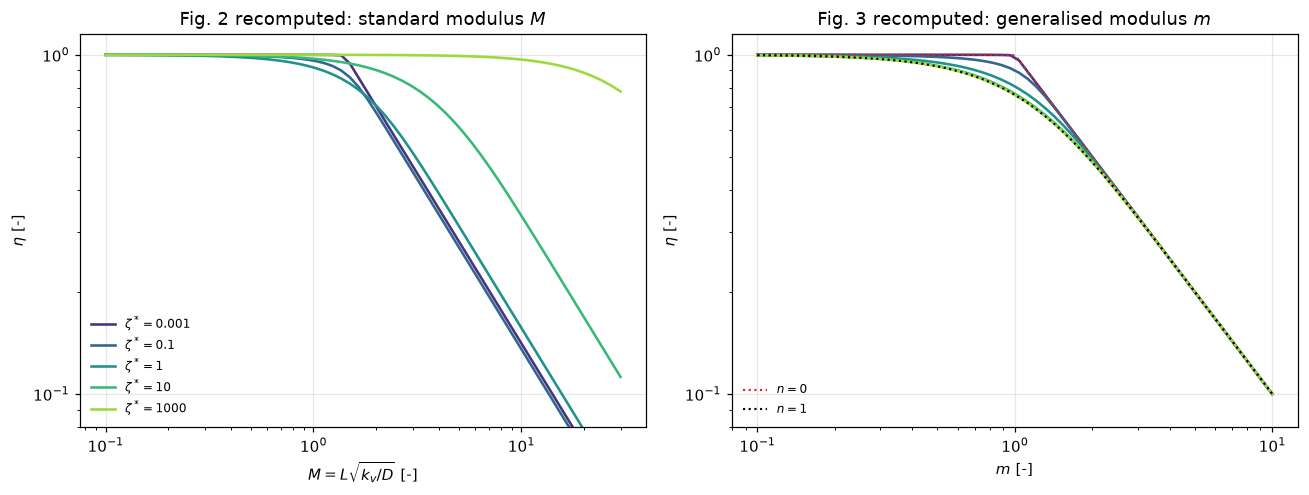

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.6))
MSTD = np.geomspace(0.1, 30.0, 60)
MM_L = np.geomspace(0.1, 10.0, 60)
sel = [0.001, 0.1, 1.0, 10.0, 1000.0]
shades = plt.cm.viridis(np.linspace(0.15, 0.85, len(sel)))
for z, col in zip(sel, shades):
    axes[0].loglog(MSTD, [LCURVES[z].eta(M * m_over_M(z)) for M in MSTD],
                   color=col, lw=1.7, label=rf"$\zeta^* = {z:g}$")
    axes[1].loglog(MM_L, [LCURVES[z].eta(m) for m in MM_L], color=col, lw=1.7)
axes[1].loglog(MM, ETA_TAB[0.0], ":", color="tab:red", lw=1.4, label="$n=0$")
axes[1].loglog(MM, ETA_TAB[1.0], ":", color="k", lw=1.4, label="$n=1$")
for ax, ttl, xl in ((axes[0], "Fig. 2 recomputed: standard modulus $M$",
                     r"$M = L\sqrt{k_v/D}$ [-]"),
                    (axes[1], "Fig. 3 recomputed: generalised modulus $m$", r"$m$ [-]")):
    ax.set_xlabel(xl)
    ax.set_ylabel(r"$\eta$ [-]")
    ax.set_ylim(0.08, 1.15)
    ax.set_title(ttl)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

In [17]:
_near0 = abs(BAND_L - BAND_30) < abs(BAND_L - BAND_15)
_near0_f = abs(BAND_LF - BAND_30_FRAC) < abs(BAND_LF - BAND_15_FRAC)
claims.exact("lhhw_nearer_zero_order_band_both_readings", bool(_near0 and _near0_f))
display(Markdown(
    f"In either reading the LHHW band on $m$ lies between the two simple-order bands: "
    f"{BAND_L:.1%} against {BAND_15:.1%} and {BAND_30:.1%} as $\\eta_{{\\max}}/\\eta_{{\\min}}-1$, "
    f"{BAND_LF:.1%} against {BAND_15_FRAC:.1%} and {BAND_30_FRAC:.1%} as a fraction of the upper "
    f"curve, and in both nearer the band that includes zero order. That is expected: "
    f"$\\zeta^* \\to 0$ is zero order over most of the pellet and $\\zeta^*\\to\\infty$ is "
    f"first order, so the family fills the $n\\in[0,1]$ part of Figure 1. \"Again about "
    f"the same\" holds against the zero-order-included figure, read the same way as the "
    f"family, not against the 15% one. On the standard modulus the family never "
    f"coincides: a factor of {max(_r) / min(_r):.0f} separates the outermost curves at "
    f"large $M$, which is what eq. (31) removes."))

In either reading the LHHW band on $m$ lies between the two simple-order bands: 30.2% against 14.6% and 40.6% as $\eta_{\max}/\eta_{\min}-1$, 23.2% against 12.7% and 28.9% as a fraction of the upper curve, and in both nearer the band that includes zero order. That is expected: $\zeta^* \to 0$ is zero order over most of the pellet and $\zeta^*\to\infty$ is first order, so the family fills the $n\in[0,1]$ part of Figure 1. "Again about the same" holds against the zero-order-included figure, read the same way as the family, not against the 15% one. On the standard modulus the family never coincides: a factor of 23 separates the outermost curves at large $M$, which is what eq. (31) removes.

### Volume change, Table 1, and a cell that fails its own equation

The variable-diffusivity case is where the $D(\alpha)$ inside eq. (13) is
*live* (everywhere else on this page it is a constant that cancels). The
paper's claim: with the correction factor of eq. (33), Thiele's
volume-change curves "again fall within the range of Figure 1." Table 1
compares eq. (33) with Hawthorn's empirical eq. (34) and says "the two are
essentially equivalent numerically." Both closed forms are evaluated below
beside the printed cells, which are **loaded from the transcription CSV,
never retyped**.

In [18]:
VCURVES = {w: Curve(VolChange(w)) for w in W_FAM}


def vc_on_m(w, m, d_in_modulus=True):
    """eta of curve w at the abscissa eq. (13) assigns; without D in the rate
    integral the abscissa is m sqrt(int r / int D r) of the true one."""
    scale = 1.0 if d_in_modulus else np.sqrt(0.5 / VolChange(w).Rint(0.0, 1.0))
    return VCURVES[w].eta(m / scale)


def vc_dev(m, d_in_modulus=True):
    e1 = CURVES[1.0].eta(m)
    return max(abs(vc_on_m(w, m, d_in_modulus) / e1 - 1) for w in W_FAM)


def vc_margin(m, d_in_modulus=True):
    """Distance to the [n = 3, n = 0] envelope as a fraction of its local width."""
    lo, hi = CURVES[3.0].eta(m), CURVES[0.0].eta(m)
    return min(min(vc_on_m(w, m, d_in_modulus) - lo, hi - vc_on_m(w, m, d_in_modulus))
               for w in W_FAM) / (hi - lo)


M_VC, VC_DEV = maximise(vc_dev, 0.2, 8.0)
M_SCAN = np.geomspace(0.2, 8.0, 41)
MARGINS = np.array([vc_margin(m) for m in M_SCAN])
claims.value("volchange_dev_from_n1_curve", VC_DEV, rtol=1e-3)
claims.count("volchange_scan_points_outside_envelope", -MARGINS, 0.0, min_margin=1e-6,
             note="41 moduli from 0.2 to 8; margin: the smallest distance to an edge over the band width")
claims.value("volchange_margin_at_m8_frac_of_band", vc_margin(8.0), rtol=1e-3)
claims.value("volchange_margin_at_kink_frac_of_band", vc_margin(1.0), rtol=1e-3)
assert vc_margin(1.0) <= MARGINS[M_SCAN <= 2.0].min(), "the kink is the smallest margin on m <= 2"
print(f"volume-change family (omega C_o = {list(W_FAM)}) on m:")
print(f"  largest deviation from the constant-D first-order curve: {VC_DEV:.2%} at m = {M_VC:.3f}")
print(f"  inside the Figure-1 envelope [n = 3, n = 0] at all {len(M_SCAN)} moduli from 0.2 to 8; the "
      f"distance to the nearer edge, as a fraction of the local band width:")
for m in (0.2, 0.5, 1.0, 2.0, 4.0, 8.0):
    print(f"    m = {m:4.1f}: {vc_margin(m):.2e}")
print(f"  on m <= 2 at least {vc_margin(1.0):.1%} (the minimum, at the kink m = 1); above, the "
      f"curves approach the upper edge eta = 1/m and the distance shrinks with m "
      f"({claims['volchange_margin_at_m8_frac_of_band']:.1e} at m = 8)")

volume-change family (omega C_o = [0.4, 1.0, -0.5, -0.25]) on m:
  largest deviation from the constant-D first-order curve: 3.18% at m = 1.101
  inside the Figure-1 envelope [n = 3, n = 0] at all 41 moduli from 0.2 to 8; the distance to the nearer edge, as a fraction of the local band width:
    m =  0.2: 1.76e-01
    m =  0.5: 1.50e-01
    m =  1.0: 9.78e-02
    m =  2.0: 2.29e-01
    m =  4.0: 8.21e-03
    m =  8.0: 3.05e-06
  on m <= 2 at least 9.8% (the minimum, at the kink m = 1); above, the curves approach the upper edge eta = 1/m and the distance shrinks with m (3.1e-06 at m = 8)


In [19]:
TAB1_W = tab1["omega_co"].to_numpy()


def table1_devs(root=0.5, exponent=0.7):
    d33 = (tab1["eq33_printed"].to_numpy() - np.array([eq33(w, root) for w in TAB1_W]))
    d34 = (tab1["eq34_printed"].to_numpy() - np.array([eq34(w, exponent) for w in TAB1_W]))
    return (d33 / np.array([eq33(w, root) for w in TAB1_W]),
            d34 / np.array([eq34(w, exponent) for w in TAB1_W]))


D33, D34 = table1_devs()
TAB1_STR = load_data("bischoff-table1.csv", page=PAGE, dtype=str)


def table1_ulp_ratios(root=0.5, exponent=0.7):
    """|printed - exact| over half a unit of the printed last digit, all eight cells."""
    out = []
    for col, f in (("eq33_printed", lambda w: eq33(w, root)), ("eq34_printed", lambda w: eq34(w, exponent))):
        for w_s, p_s in zip(TAB1_STR["omega_co"], TAB1_STR[col]):
            half = 0.5 * 10.0 ** -len(p_s.partition(".")[2])
            out.append(abs(float(p_s) - f(float(w_s))) / half)
    return np.array(out)


N_OUT = claims.count("table1_cells_outside_rounding", table1_ulp_ratios(), 1.0, min_margin=0.01,
                     note="cells whose gap to the equation exceeds half a unit of the printed digit")
_ok = TAB1_W != -0.25
claims.value("table1_eq33_three_cells_worst_rel", np.abs(D33[_ok]).max(), rtol=1e-3)
claims.value("table1_eq33_defect_cell_rel", abs(D33[~_ok][0]), rtol=1e-3)
claims.value("table1_eq33_defect_cell_abs", abs(D33[~_ok][0]) * eq33(-0.25), rtol=1e-3)
claims.value("table1_eq34_worst_rel", np.abs(D34).max(), rtol=1e-3)
claims.value("table1_eq33_at_wco_minus_0p25", eq33(-0.25), rtol=1e-6)
claims.value("table1_eq33_defect_halfunit_multiple", claims["table1_eq33_defect_cell_abs"] / 0.0005,
             rtol=1e-3)
print("Bischoff Table 1, printed against recomputed:")
print(f"{'wCo':>7}{'eq33 printed':>14}{'eq33 exact':>12}{'dev':>9}"
      f"{'eq34 printed':>14}{'eq34 exact':>12}{'dev':>9}")
for (w, p33, p34), r33, r34 in zip(tab1[["omega_co", "eq33_printed", "eq34_printed"]].to_numpy(),
                                   D33, D34):
    print(f"{w:7.2f}{p33:14.3f}{eq33(w):12.4f}{r33:+9.4f}{p34:14.3f}{eq34(w):12.4f}{r34:+9.4f}"
          + ("   <--" if abs(r33) > 0.004 else ""))
_abs = claims["table1_eq33_defect_cell_abs"]
_printed = float(tab1.loc[~_ok, "eq33_printed"].iloc[0])
print(f"eq. (33): three cells agree to {claims['table1_eq33_three_cells_worst_rel']:.4f}, inside "
      f"three-digit rounding; the omega C_o = -0.25 cell is off by {_abs:.4f} absolute")
print(f"({claims['table1_eq33_defect_cell_rel']:.4f} relative), {claims['table1_eq33_defect_halfunit_multiple']:.0f}x the half-unit "
      f"rounding radius of a printed {_printed:.3f} (the same {claims['table1_eq33_defect_cell_rel'] / (0.0005 / _printed):.0f}x with both sides relative)")
print(f"eq. (34) agrees to {claims['table1_eq34_worst_rel']:.4f} in all four cells, this row included "
      f"({float(tab1.loc[~_ok, 'eq34_printed'].iloc[0]):.3f} against {eq34(-0.25):.4f}),")
print(f"so the row's omega C_o label is right and the defect is one cell: printed {_printed:.3f}, "
      f"eq. (33) gives {eq33(-0.25):.4f}. Reported, not repaired.")

Bischoff Table 1, printed against recomputed:
    wCo  eq33 printed  eq33 exact      dev  eq34 printed  eq34 exact      dev
   0.40         1.120      1.1222  -0.0019         1.130      1.1287  +0.0012
   1.00         1.280      1.2765  +0.0027         1.290      1.2925  -0.0019
  -0.50         0.804      0.8045  -0.0006         0.796      0.7956  +0.0005
  -0.25         0.905      0.9107  -0.0062         0.906      0.9064  -0.0004   <--
eq. (33): three cells agree to 0.0027, inside three-digit rounding; the omega C_o = -0.25 cell is off by 0.0057 absolute
(0.0062 relative), 11x the half-unit rounding radius of a printed 0.905 (the same 11x with both sides relative)
eq. (34) agrees to 0.0019 in all four cells, this row included (0.906 against 0.9064),
so the row's omega C_o label is right and the defect is one cell: printed 0.905, eq. (33) gives 0.9107. Reported, not repaired.


The glyphs are crisp at digit scale (`0.905` is not an OCR question), and the
constraint that decides the cell is arithmetic: the other three cells of the
same column pin the transcription of eq. (33) to within printed rounding, the
neighbouring eq. (34) column pins the row label $\omega C_o = -0.25$, and
eq. (33) itself then gives a different number. A slip in the fourth cell of a
1965 table, visible only because the equation beside it is closed-form.

The physics survives the cell: the volume-change family sits inside the
Figure-1 envelope (the paper's claim) and stays close to the first-order
curve. The $D(\alpha)$ weighting inside eq. (13) is what does it: the break
table drops that weighting and the collapse fails.

### The $n=1/2$ reduction, exactly as printed, is a misprint

Eq. (27) with its where-block reads

$$m = \tfrac{3}{2}\sqrt{C_L/C_o}\;\tfrac{1}{\sqrt[4]{3}}
\Bigl[(1+\sqrt3)F(\phi,k) - 2\sqrt3\,E(\phi,k)
+ 2\sqrt3\,\tfrac{\sin\phi\sqrt{1-k^2\sin^2\phi}}{1+\cos\phi}\Bigr],\quad
\sin\phi = \tfrac{\sqrt{4\sqrt3\,(C_o/C_L-1)}}{\sqrt3-1+C_o/C_L},\;
k=\sin 15°,$$

the $\sin\phi$ block being *the same one printed under the $n=2$ case*. But
the $n=1/2$ integral $\int\mathrm{d}t/\sqrt{t^{3/2}-1}$ reduces through the
substitution $y=\sqrt t$, which changes both the prefactor exponent and the
argument $\phi$ is built on. As printed, the formula contradicts the paper's
own eq. (20), from which it is derived, across the whole curve; amended in
exactly those two places (prefactor $(C_L/C_o)^{1/4}$, $\phi$ built on
$\sqrt{C_o/C_L}$), it agrees with eq. (20) and with Route B. Both versions
share the bracket, so the defect cannot be in this page's transcription of the
$F$/$E$ combination.

In [20]:
U27 = (0.05, 0.1, 0.3, 0.5, 0.7, 0.9)


def eq27_devs(printed):
    return np.array([abs(m_eta_nhalf(u, printed)[0] / m_eq20(0.5, u) - 1) for u in U27])


ASP, AMD = eq27_devs(True), eq27_devs(False)
claims.value("eq27_as_printed_worst_rel_m", ASP.max(), rtol=1e-6)
claims.value("eq27_as_printed_min_rel_m", ASP.min(), rtol=1e-6)
claims.bound("eq27_amended_worst_rel_m", AMD.max(), max=1e-12, basis="tolerance",
             note="eq. (20) is a quadrature at epsrel 1e-11; the closed form is exact")
print(f"{'u = C_L/C_o':>12}{'eq. (20)':>12}{'as printed':>12}{'rel dev':>9}{'amended':>12}")
for u, a in zip(U27, ASP):
    print(f"{u:12.2f}{m_eq20(0.5, u):12.6f}{m_eta_nhalf(u, True)[0]:12.6f}{a:9.1%}"
          f"{m_eta_nhalf(u)[0]:12.6f}")
print(f"as printed: {ASP.min():.0%} to {ASP.max():.0%} off its own eq. (20); amended: below 1e-12 "
      f"(here {AMD.max():.0e})")


def printed_ratio_dev(printed=True, u=1.0 - 1e-6):
    """|m(as printed)/m(eq. 20) - sqrt 2| near the kinetic end u -> 1."""
    return abs(m_eta_nhalf(u, printed)[0] / m_eq20(0.5, u) - np.sqrt(2.0))


def eta_nhalf_closed(m, printed):
    u = brentq(lambda u: m_eta_nhalf(u, printed)[0] - m, 1e-9, 1 - 1e-9, xtol=1e-13)
    return m_eta_nhalf(u, printed)[1]


def band_with_nhalf(m, printed=True):
    v = [eta_nhalf_closed(m, printed)] + [CURVES[n].eta(m) for n in (1.0, 2.0, 3.0)]
    return max(v) / min(v) - 1.0


claims.bound("eq27_printed_ratio_limit_dev", printed_ratio_dev(), max=1e-6, basis="theory",
             note="m(as printed)/m(eq. 20) -> sqrt 2 as u -> 1; at u = 1 - 1e-6")
claims.value("band_asprinted_nhalf_would_give", band_with_nhalf(0.05), rtol=1e-4)
print("m(as printed)/m(eq. 20) toward the kinetic end:")
for uu in (0.99, 0.999, 1.0 - 1e-6):
    print(f"  u = {uu}: {m_eta_nhalf(uu, True)[0] / m_eq20(0.5, uu):.7f}")
print(f"  -> sqrt(2) = {np.sqrt(2):.7f}, within 1e-6 at u = 1 - 1e-6 "
      f"(here {claims['eq27_printed_ratio_limit_dev']:.0e})")
print(f"so the as-printed curve gives eta = {eta_nhalf_closed(0.05, True):.4f} at m = 0.05, not "
      f"about 1, and with the other three orders the band there is "
      f"{claims['band_asprinted_nhalf_would_give']:.1%}")
print(f"(it tends to sqrt(2) - 1 = {np.sqrt(2) - 1:.1%} as m -> 0), against {BAND_15:.1%} at "
      f"its largest for the amended curve.")

 u = C_L/C_o    eq. (20)  as printed  rel dev     amended
        0.05    1.937165    2.498971    29.0%    1.937165
        0.10    1.730482    2.291191    32.4%    1.730482
        0.30    1.289512    1.764651    36.8%    1.289512
        0.50    0.993931    1.376510    38.5%    0.993931
        0.70    0.721337    1.007645    39.7%    0.721337
        0.90    0.395836    0.557486    40.8%    0.395836
as printed: 29% to 41% off its own eq. (20); amended: below 1e-12 (here 1e-15)
m(as printed)/m(eq. 20) toward the kinetic end:
  u = 0.99: 1.4136249
  u = 0.999: 1.4141546
  u = 0.999999: 1.4142135
  -> sqrt(2) = 1.4142136, within 1e-6 at u = 1 - 1e-6 (here 6e-08)
so the as-printed curve gives eta = 0.7069 at m = 0.05, not about 1, and with the other three orders the band there is 41.3%
(it tends to sqrt(2) - 1 = 41.4% as m -> 0), against 14.6% at its largest for the amended curve.


The paper never prints a number for the $n=1/2$ curve (no table touches it;
its only appearance is Figure 1), so the misprint is invisible to a reader who
does not re-derive the reduction, and anyone *implementing eqs. (27)-(28) as
printed gets a curve that is 29-41% off in $m$* over the centre
concentrations sampled above. The printed "about 15%" is
what shows that Bischoff's own Figure 1 did not use the printed formula: the
as-printed curve tops out at $\eta = 1/\sqrt2$ instead of 1, so the
half-to-third band it implies is already about 41% at the kinetic end, where
the true band closes to zero, irreconcilable with any reading of 15%. The
amendment is an inference, labelled as such; the band numbers above use
Route B, not eq. (27).

In [21]:
claims.says("29%", "eq27_as_printed_min_rel_m")
claims.says("41%", "eq27_as_printed_worst_rel_m")
claims.says("41%", "band_asprinted_nhalf_would_give")

True

### Eq. (14) as printed carries a defect of the same kind

Route B integrates eqs. (14)-(15) and reads eq. (14)'s denominator bracket as
$[\int_0^{C_o}D\,r\,\mathrm{d}C]^{+1/2}$, because that is what eqs. (8) and
(13), of which eq. (14) is the stated combination, force. **As printed, that
denominator bracket carries exponent $-1/2$** (read at digit scale from the
native 300 ppi render; the *inner* bracket in the numerator correctly prints
$-1/2$, so the defect is isolated to one exponent). Dividing by
$[\,\cdot\,]^{-1/2}$ multiplies by the rate integral to the $+1/2$: as printed
the equation is dimensionally inconsistent ($m$ would carry the units of
$D\,r\,C$) and, in this page's normalised variables, low by exactly the
factor $I_0 = \int_0^1\tilde r\,\mathrm{d}c = 1/(n+1)$ for order $n$. The
paper's own eq. (21) is the witness.

In [22]:
def eq14_devs(denominator_exponent=-0.5, u=0.5):
    """Relative shortfall of m from eq. (14) with the given exponent, per order."""
    return {n: abs(mb_eta(Power(n), u, denominator_exponent)[0] / mb_eta(Power(n), u)[0] - 1)
            for n in KEYS_15}


EQ14 = eq14_devs()
claims.value("eq14_as_printed_worst_rel_m", max(EQ14.values()), rtol=1e-6)
print("eq. (14) as printed against its parents eqs. (8) + (13), at u = 0.5:")
for n, d in EQ14.items():
    print(f"  n = {n:g}: I0 = {Power(n).Rint(0.0, 1.0):.4f}, as-printed m low by {d:.0%} "
          f"(= 1 - I0, independent of u)")
print(f"the printed witness: eq. (21) gives m = arccosh(1/u) = {m_eta_n1(0.5)[0]:.6f} at u = 0.5, "
      f"eq. (14) as printed {mb_eta(Power(1), 0.5, -0.5)[0]:.6f}, half of it.")
print("Route B implements the +1/2 reading; its agreement with the printed closed forms")
print("(first Results cell) is the proof that reading is right for every order.")

eq. (14) as printed against its parents eqs. (8) + (13), at u = 0.5:
  n = 0.5: I0 = 0.6667, as-printed m low by 33% (= 1 - I0, independent of u)
  n = 1: I0 = 0.5000, as-printed m low by 50% (= 1 - I0, independent of u)
  n = 2: I0 = 0.3333, as-printed m low by 67% (= 1 - I0, independent of u)
  n = 3: I0 = 0.2500, as-printed m low by 75% (= 1 - I0, independent of u)
the printed witness: eq. (21) gives m = arccosh(1/u) = 1.316958 at u = 0.5, eq. (14) as printed 0.658479, half of it.
Route B implements the +1/2 reading; its agreement with the printed closed forms
(first Results cell) is the proof that reading is right for every order.


### Out of sample: a finite cylinder, and a 1998 competitor

Bischoff's collapse plus Aris's length ($L = v_p/s_x$, page
[`B1.2`](../B1.2-aris-shape-factor/)) yields a zero-cost estimate for *any*
shape and *any* kinetics: compute $m$ with eq. (13), read $\eta$ off the
Figure-1 band. The audit takes a case neither 1965 source computed: a
finite cylinder ($Z = H/2R_p = 1$, every face active), first- and
second-order kinetics, solved here as a 2-D pymrm problem (`Cyl2D`: `nu=1`
radial axis times a Cartesian axial axis, the `B1.2` operators with a Newton
solve on the reaction).

The competitor: Pan & Zhu (1998) propose, for **arbitrary kinetics** in
exactly this geometry, the polynomial
$\eta_a = q_1\eta_{sp} + q_2\eta_{sp}^2 + q_3\eta_{sp}^3$ in the basis
$\eta_{sp} = (\coth\phi - 1/\phi)/\phi$, with the $q_i$ fixed by matching
their exact $\phi\to0$ perturbation ($\mu_1$, their eq. 26) and $\phi\to\infty$
asymptote ($\mu_2 Q_2/\phi$, their eq. 29), the large-$\phi$ end being
*Bischoff's asymptotic solution in a cylinder*: their
$Q_2 = [\,2\int_{C_{eq}}^{1} r\,\mathrm{d}C]^{1/2}$ is eq. (11)'s integral.
They claim "a maximum deviation of less than 1.5% from analytical solutions
or numerical calculation results ... for arbitrary kinetics" (abstract), and
their printed tests are first order (their Table 6) and one steam-shift case
(their Table 7). Both endpoint coefficients are recomputed here from their
printed definitions; the matching that yields $q_2, q_3$ is re-derived and
asserted rather than copied, which matters because their printed eq. (36)
has a sign error (shown below).

In [23]:
claims.value("pan_mu1_vs_table5_worst_abs",
             max(abs(mu1_series(Z) - v) for Z, v in zip(pan5["Z"], pan5["mu1_printed"])),
             rtol=1e-3)
claims.bound("mu1_series_truncation", max(abs(mu1_series(Z) - mu1_series(Z, 400, 800))
                                          for Z in pan5["Z"]),
             max=1e-8, basis="chosen", note="doubling both term counts; Table 5 prints 4 digits")
_mu2_row = pan5.loc[pan5["Z"] == 2.5].iloc[0]
claims.value("pan_mu2_z25_defect_abs", abs(_mu2_row["mu2_printed"] - mu2_eq30(2.5)), rtol=1e-6)
print(f"Pan & Zhu Table 5: mu1 by their eq. (26) series reproduces the row to "
      f"{claims['pan_mu1_vs_table5_worst_abs']:.1e} (worst cell; the series is truncated below "
      f"1e-8, here {claims['mu1_series_truncation']:.0e})")
_ok2 = [Z for Z, v in zip(pan5["Z"], pan5["mu2_printed"]) if abs(v - mu2_eq30(Z)) < 0.006]
print(f"mu2 against their eq. (30), 2 + 1/Z: {len(_ok2)} of {len(pan5)} cells within the "
      f"printed rounding; Z = 2.5 prints {_mu2_row['mu2_printed']:.2f}, eq. (30) gives "
      f"{mu2_eq30(2.5):.2f} (the Z = 2.0 cell is {float(pan5.loc[pan5['Z'] == 2.0, 'mu2_printed'].iloc[0]):.2f}).")
print("Their Table 6 below uses Z = 1 and 2 only. Reported, not repaired.")

_e3 = eta_pz(3.0, 1.0, 1.0, 1.0, sign405=-1)
claims.value("pan_eq36_as_printed_eta_a_phi3", _e3, rtol=1e-3)
print(f"their eq. (36) prints q3 = -54 - 405 mu1 Q1 + 9 mu2 Q2 (600 ppi crop); with that sign, "
      f"first order at Z = 1, phi = 3 gives eta_a = {_e3:.3f},")
print(f"where their Table 6 prints {float(pan6.loc[(pan6['Z'] == 1.0) & (pan6['phi'] == 3.0), 'eta_a_printed'].iloc[0]):.3f}. "
      f"The matching conditions they state force +405 (asserted in pz_coeffs), and with it")
print("their printed eta_a column returns (next cell): a sign misprint, shown by the paper's own numbers.")

Pan & Zhu Table 5: mu1 by their eq. (26) series reproduces the row to 5.1e-05 (worst cell; the series is truncated below 1e-8, here 2e-09)
mu2 against their eq. (30), 2 + 1/Z: 8 of 9 cells within the printed rounding; Z = 2.5 prints 2.50, eq. (30) gives 2.40 (the Z = 2.0 cell is 2.50).
Their Table 6 below uses Z = 1 and 2 only. Reported, not repaired.
their eq. (36) prints q3 = -54 - 405 mu1 Q1 + 9 mu2 Q2 (600 ppi crop); with that sign, first order at Z = 1, phi = 3 gives eta_a = -0.031,
where their Table 6 prints 0.653. The matching conditions they state force +405 (asserted in pz_coeffs), and with it
their printed eta_a column returns (next cell): a sign misprint, shown by the paper's own numbers.


In [24]:
T6 = pan6[pan6["Z"] == 1.0]


def table6_devs(sign405=+1, bessel_order=0):
    mu1 = mu1_series(1.0, bessel_order=bessel_order)
    ea = [abs(eta_pz(p, 1.0, 1.0, 1.0, sign405, mu1) - v)
          for p, v in zip(T6["phi"], T6["eta_a_printed"])]
    es = [abs(eta_series_1st(p, 1.0, bessel_order=bessel_order) - v)
          for p, v in zip(T6["phi"], T6["eta_star_printed"])]
    return max(ea), max(es)


DEV_EA, DEV_ES = table6_devs()
claims.value("pan_table6_eta_a_reproduced_worst_abs", DEV_EA, rtol=1e-3)
claims.value("pan_table6_eta_star_reproduced_worst_abs", DEV_ES, rtol=1e-3)
claims.bound("eta_series_truncation_worst",
             max(abs(eta_series_1st(p) / eta_series_1st(p, 1.0, 400, 800) - 1)
                 for p in (0.5, 1.0, 2.0, 4.0, 8.0)),
             max=1e-6, basis="chosen", note="doubling both term counts, phi up to 8")
print("Pan & Zhu Table 6 at Z = 1 (printed values loaded, never retyped):")
print(f"{'phi':>6}{'eta_a printed':>15}{'eq.32 here':>12}{'eta* printed':>14}{'eq.37 here':>12}")
for p, a, s in T6[["phi", "eta_a_printed", "eta_star_printed"]].to_numpy():
    print(f"{p:6.1f}{a:15.3f}{eta_pz(p, 1.0, 1.0, 1.0):12.4f}{s:14.3f}{eta_series_1st(p):12.4f}")
print(f"worst |printed - recomputed|: eta_a {DEV_EA:.4f}, eta* {DEV_ES:.4f} (three-decimal "
      f"rounding is 0.0005); the series is truncated below 1e-6 "
      f"(here {claims['eta_series_truncation_worst']:.0e})")


def printed_gaps(z_values=(1.0, 2.0)):
    g = pan6[pan6["Z"].isin(z_values)].assign(
        gap=lambda d: (d["eta_star_printed"] - d["eta_a_printed"]).abs())
    g["rel"] = g["gap"] / g["eta_star_printed"]
    return g


GAPS = printed_gaps()
claims.value("pan_printed_worst_pair_abs", GAPS["gap"].max(), rtol=1e-6)
claims.value("pan_printed_worst_pair_rel", GAPS["rel"].max(), rtol=1e-6)
_tied = GAPS[np.isclose(GAPS["gap"], GAPS["gap"].max())]
_j = GAPS["rel"].idxmax()
print(f"their claim, deviation < 1.5%: their worst printed absolute gap is a tie at "
      f"{GAPS['gap'].max():.3f} ("
      + "; ".join(f"Z = {r.Z:g}, phi = {r.phi:g}: {r.eta_a_printed:.3f} vs {r.eta_star_printed:.3f}"
                  for r in _tied.itertuples()) + ");")
print(f"the worst relative pair over all {len(GAPS)} is phi = {GAPS.loc[_j, 'phi']:g} "
      f"(Z = {GAPS.loc[_j, 'Z']:g}): {GAPS['rel'].max():.2%}, {GAPS['rel'].max() / 0.015:.1f} times the "
      f"advertised bound. The claim holds on their own first-order numbers only as an absolute deviation.")

Pan & Zhu Table 6 at Z = 1 (printed values loaded, never retyped):
   phi  eta_a printed  eq.32 here  eta* printed  eq.37 here
   0.5          0.982      0.9817         0.982      0.9817
   0.8          0.955      0.9550         0.955      0.9551
   1.0          0.932      0.9322         0.932      0.9324
   1.5          0.864      0.8641         0.865      0.8645
   2.0          0.790      0.7899         0.791      0.7908
   3.0          0.653      0.6527         0.655      0.6550
   4.0          0.545      0.5453         0.549      0.5486
   6.0          0.404      0.4037         0.408      0.4074
   8.0          0.319      0.3189         0.322      0.3221
worst |printed - recomputed|: eta_a 0.0003, eta* 0.0006 (three-decimal rounding is 0.0005); the series is truncated below 1e-6 (here 3e-07)
their claim, deviation < 1.5%: their worst printed absolute gap is a tie at 0.013 (Z = 2, phi = 4: 0.477 vs 0.490; Z = 2, phi = 6: 0.343 vs 0.356);
the worst relative pair over all 18 is phi = 

In [25]:
CYL = Cyl2D(N_CYL, 1.0)
PHIS = np.array([0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0])
claims.value("pymrm_cyl2d_vs_series_worst_rel",
             max(abs(CYL.eta(Power(1), p) / eta_series_1st(p) - 1) for p in PHIS))
print(f"pymrm 2-D cylinder ({N_CYL} x {N_CYL}) against the exact first-order series over "
      f"phi = 0.5 to 8: worst relative {claims['pymrm_cyl2d_vs_series_worst_rel']:.1e}")

MU2 = mu2_eq30(1.0)            # v_p/s_x = R_p/mu2 at Z = 1 (Aris's length, page B1.2)


@functools.lru_cache(maxsize=None)
def eta_cyl_n2(phi):
    """The exact second-order reference: the 2-D pymrm solve."""
    return CYL.eta(Power(2), phi)


def estimate(kind, phi, n=2):
    """The three shortcut estimates of eta on the cylinder."""
    if kind == "pz":        # Pan & Zhu eq. (32); n = 2: Q1 = 2, Q2 = sqrt(2/3)
        return eta_pz(phi, 1.0, *((2.0, np.sqrt(2.0 / 3.0)) if n == 2 else (1.0, 1.0)))
    if kind == "slab":      # Figure 1 used literally: the slab curve at m(v_p/s_x)
        return CURVES[float(n)].eta(phi / MU2 * np.sqrt((n + 1.0) / 2.0))
    if kind == "slab_Rp":   # the same with L = R_p instead of v_p/s_x
        return CURVES[float(n)].eta(phi * np.sqrt((n + 1.0) / 2.0))
    if kind == "ab":        # the cylinder's own first-order curve at equal m
        return eta_series_1st(phi * np.sqrt((n + 1.0) / 2.0), 1.0)
    if kind == "ab_std":    # the same read at the standard modulus
        return eta_series_1st(phi, 1.0)
    raise ValueError(kind)


def dev(kind, phi, relative=False, n=2):
    ex = eta_cyl_n2(phi) if n == 2 else eta_series_1st(phi)
    d = abs(estimate(kind, phi, n) - ex)
    return d / ex if relative else d


def max_dev(kind, relative=False, n=2):
    return maximise(lambda p: dev(kind, p, relative, n), 0.3, 8.0, ngrid=14)


PHI_PZ, DEV_PZ = max_dev("pz")
PHI_BI, DEV_BI = max_dev("slab")
PHI_AB, DEV_AB = max_dev("ab")
_, REL_AB = max_dev("ab", relative=True)
PHI_BI1, BI1 = max_dev("slab", n=1)
PHI_PZ1, PZ1 = max_dev("pz", n=1)
claims.value("pan_zhu_n2_out_of_sample_max_abs", DEV_PZ, rtol=1e-3)
claims.value("pan_zhu_n2_over_claimed_bound", DEV_PZ / 0.015, rtol=1e-3)
claims.value("slab_curve_estimate_cyl_n2_max_abs", DEV_BI, rtol=1e-3)
claims.value("aris_bischoff_combined_cyl_n2_max_abs", DEV_AB, rtol=1e-3)
claims.value("aris_bischoff_combined_cyl_n2_max_rel", REL_AB, rtol=1e-3)
claims.value("slab_curve_estimate_cyl_1st_max_abs", BI1, rtol=1e-3)
claims.value("pan_zhu_cyl_1st_max_abs", PZ1, rtol=1e-3)
_ref_change = max(abs(Cyl2D(2 * N_CYL).eta(Power(2), p) - eta_cyl_n2(p))
                  for p in (PHI_PZ, PHI_BI, PHI_AB))
claims.bound("cyl2d_n2_reference_grid_change", _ref_change, max=1e-4, basis="chosen",
             note="|eta(200 x 200) - eta(100 x 100)| at the three maxima; the deviations "
                  "it judges are 0.03 and above")
Q_N2 = pz_coeffs(1.0, 2.0, np.sqrt(2.0 / 3.0))
print("second order (r = c^2), Z = 1, against the 2-D pymrm solve; absolute deviations in eta:")
print(f"  Pan & Zhu eq. (32) ('arbitrary kinetics, < 1.5%'):  {DEV_PZ:.3f} at phi = {PHI_PZ:.2f}")
print(f"  slab Fig.-1 curve at m(v_p/s_x) (shape ignored):    {DEV_BI:.3f} at phi = {PHI_BI:.2f}")
print(f"  cylinder 1st-order curve at equal m (Aris+Bischoff): {DEV_AB:.3f} at phi = {PHI_AB:.2f} "
      f"({REL_AB:.1%} relative at its own maximum)")
print(f"first order, against the exact series: the slab reading errs {BI1:.3f} at phi = "
      f"{PHI_BI1:.2f} (the B1.2 shape band), Pan & Zhu {PZ1:.4f} at phi = {PHI_PZ1:.2f} "
      f"(their tested case)")
print(f"Pan & Zhu's matched coefficients at Q1 = 2, Q2 = sqrt(2/3): q1 = {Q_N2[0]:.2f}, "
      f"q2 = {Q_N2[1]:.2f}, q3 = {Q_N2[2]:.2f}")
print(f"the 2-D reference changes by less than 1e-4 on 200 x 200 cells (here {_ref_change:.0e}, "
      f"{DEV_AB / _ref_change:.0f} times below the smallest deviation it judges)")

pymrm 2-D cylinder (100 x 100) against the exact first-order series over phi = 0.5 to 8: worst relative 6.3e-05


second order (r = c^2), Z = 1, against the 2-D pymrm solve; absolute deviations in eta:
  Pan & Zhu eq. (32) ('arbitrary kinetics, < 1.5%'):  0.090 at phi = 3.79
  slab Fig.-1 curve at m(v_p/s_x) (shape ignored):    0.099 at phi = 2.47
  cylinder 1st-order curve at equal m (Aris+Bischoff): 0.030 at phi = 1.78 (4.4% relative at its own maximum)
first order, against the exact series: the slab reading errs 0.108 at phi = 3.33 (the B1.2 shape band), Pan & Zhu 0.0037 at phi = 5.47 (their tested case)
Pan & Zhu's matched coefficients at Q1 = 2, Q2 = sqrt(2/3): q1 = 2.45, q2 = -8.00, q3 = 28.94
the 2-D reference changes by less than 1e-4 on 200 x 200 cells (here 2e-05, 1605 times below the smallest deviation it judges)


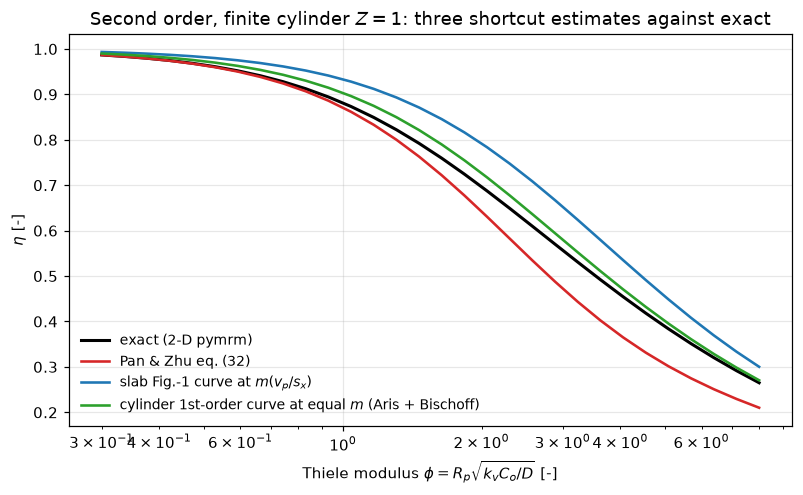

In [26]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
pp = np.geomspace(0.3, 8.0, 30)
ax.semilogx(pp, [eta_cyl_n2(p) for p in pp], "k-", lw=2.0, label="exact (2-D pymrm)")
for kind, col, lab in (("pz", "tab:red", "Pan & Zhu eq. (32)"),
                       ("slab", "tab:blue", "slab Fig.-1 curve at $m(v_p/s_x)$"),
                       ("ab", "tab:green", "cylinder 1st-order curve at equal $m$ (Aris + Bischoff)")):
    ax.semilogx(pp, [estimate(kind, p) for p in pp], "-", color=col, lw=1.7, label=lab)
ax.set_xlabel(r"Thiele modulus $\phi = R_p\sqrt{k_v C_o/D}$ [-]")
ax.set_ylabel(r"$\eta$ [-]")
ax.set_title("Second order, finite cylinder $Z=1$: three shortcut estimates against exact")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

In [27]:
display(Markdown(
    f"The audit separates along the two error axes. **Pan & Zhu's polynomial handles "
    f"the shape and fails on the kinetics**: advertised for arbitrary kinetics with "
    f"\"maximum deviation of less than 1.5%\", it does well where they tested it (first "
    f"order: {PZ1:.4f} worst here, as in their Table 6), but for a second-order reaction "
    f"its midrange deviation reaches {DEV_PZ:.3f} absolute in $\\eta$, "
    f"{DEV_PZ / 0.015:.0f} times their claimed bound even read as an absolute deviation, "
    f"because the cubic in $\\eta_{{sp}}$ is controlled only at its two ends, and "
    f"$Q_1 = 2$ puts large coefficients of opposite sign ($q_2 = {Q_N2[1]:.2f}$, "
    f"$q_3 = {Q_N2[2]:.2f}$) between them. **Reading Bischoff's Figure 1 literally fails "
    f"on the shape**: the slab curve at $m(v_p/s_x)$ errs by up to {DEV_BI:.3f} for "
    f"$n = 2$ and {BI1:.3f} for first order, which is the shape band `B1.2` measured, "
    f"not a kinetics error. **The combination both 1965 papers point to, the shape's own "
    f"first-order curve read at Bischoff's generalised modulus, does best**: "
    f"{DEV_AB:.3f} absolute, {REL_AB:.1%} relative, inside the advertised 15% band, "
    f"with no fitted constant. The approximation with the 10 times tighter claim is the "
    f"one that breaks; the page states this only for the kinetics tested here "
    f"($n = 2$, $Z = 1$).\n\n"
    f"Two further printed defects surfaced in the secondary source, both shown from "
    f"the paper's own numbers above: Table 5's $\\mu_2$ at $Z = 2.5$ (prints "
    f"{_mu2_row['mu2_printed']:.2f}; their eq. 30 gives {mu2_eq30(2.5):.2f}), and eq. (36)'s "
    f"$-405\\mu_1Q_1$ (the matching conditions they state force $+405$; the printed sign "
    f"makes their own Table 6 column negative). Reported, not repaired: the amended "
    f"sign is used, labelled as an inference forced by their stated construction."))

The audit separates along the two error axes. **Pan & Zhu's polynomial handles the shape and fails on the kinetics**: advertised for arbitrary kinetics with "maximum deviation of less than 1.5%", it does well where they tested it (first order: 0.0037 worst here, as in their Table 6), but for a second-order reaction its midrange deviation reaches 0.090 absolute in $\eta$, 6 times their claimed bound even read as an absolute deviation, because the cubic in $\eta_{sp}$ is controlled only at its two ends, and $Q_1 = 2$ puts large coefficients of opposite sign ($q_2 = -8.00$, $q_3 = 28.94$) between them. **Reading Bischoff's Figure 1 literally fails on the shape**: the slab curve at $m(v_p/s_x)$ errs by up to 0.099 for $n = 2$ and 0.108 for first order, which is the shape band `B1.2` measured, not a kinetics error. **The combination both 1965 papers point to, the shape's own first-order curve read at Bischoff's generalised modulus, does best**: 0.030 absolute, 4.4% relative, inside the advertised 15% band, with no fitted constant. The approximation with the 10 times tighter claim is the one that breaks; the page states this only for the kinetics tested here ($n = 2$, $Z = 1$).

Two further printed defects surfaced in the secondary source, both shown from the paper's own numbers above: Table 5's $\mu_2$ at $Z = 2.5$ (prints 2.50; their eq. 30 gives 2.40), and eq. (36)'s $-405\mu_1Q_1$ (the matching conditions they state force $+405$; the printed sign makes their own Table 6 column negative). Reported, not repaired: the amended sign is used, labelled as an inference forced by their stated construction.

### Cross-check against `B1.1`, and the exported curves

`B1.1` ships the exact isothermal $\eta(\phi)$ for Thiele's three geometries.
For a first-order slab Bischoff's $m$ *is* Thiele's $\phi$ (eq. 17 at
$n = 1$), so that page's slab rows must coincide with this page's $n=1$ curve:
a check of the loading and the modulus convention (length on the half-width,
no factor $\sqrt 2$ adrift). Both sides are $\tanh\phi/\phi$, so the gap can
only come from the stored digits; the check below bounds each row's gap by the
rounding of its stored $\phi$ and $\eta$.

In [28]:
def b11_check(phi_factor=1.0):
    raw = load_data("isothermal-exact.csv", page="B1.1-thiele-weisz-hicks", dtype=str)
    rows = raw[raw["geometry"] == "slab"]
    worst, ratio, used = 0.0, 0.0, 0
    for p_s, e_s in zip(rows["phi"], rows["eta"]):
        p, e = float(p_s), float(e_s)
        if not 0.1 <= p <= 20:
            continue
        used += 1
        m = phi_factor * p
        ex = CURVES[1.0].eta(m)
        slope = abs((1.0 / np.cosh(m) ** 2 - np.tanh(m) / m) / m) * phi_factor   # d eta/d phi
        half = lambda s: 0.5 * 10.0 ** -len(s.partition(".")[2])
        worst = max(worst, abs(e / ex - 1))
        ratio = max(ratio, abs(e - ex) / (slope * half(p_s) + half(e_s)))
    return worst, ratio, used


B11_DEV, B11_RATIO, B11_N = b11_check()
claims.value("b11_slab_reconciliation_worst_rel", B11_DEV)
claims.bound("b11_slab_gap_over_stored_rounding", B11_RATIO, max=1.0, basis="theory",
             note="|gap| <= |d eta/d phi| half-unit(phi) + half-unit(eta), per row")
print(f"B1.1 slab table against this page's n = 1 curve at m = phi: {B11_N} rows with "
      f"0.1 <= phi <= 20, worst relative "
      f"{B11_DEV:.1e}; every gap is within the rounding of the stored digits "
      f"(here at most {B11_RATIO:.2f} of it)")

B1.1 slab table against this page's n = 1 curve at m = phi: 41 rows with 0.1 <= phi <= 20, worst relative 3.4e-06; every gap is within the rounding of the stored digits (here at most 0.98 of it)


In [29]:
M_EXPORT = np.round(np.geomspace(0.1, 20.0, 61), 10)
EXPORT = ([("power", f"{n:g}", m, CURVES[n].eta(m)) for n in KEYS_30 for m in M_EXPORT]
          + [("lhhw", f"{z:g}", m, LCURVES[z].eta(m)) for z in (0.01, 0.1, 1.0, 10.0, 100.0)
             for m in M_EXPORT]
          + [("volchange", f"{w:g}", m, VCURVES[w].eta(m)) for w in W_FAM for m in M_EXPORT])


def closed_eta(n, m):
    """eta(m) of order n from Route C."""
    if n == 0.0:
        return 1.0 if m < 1.0 else 1.0 / m
    if n == 1.0:
        return np.tanh(m) / m
    if n == 0.5 and m >= mstar_power(0.5):
        return 1.0 / m
    f = CLOSED[n]
    u = brentq(lambda v: f(1.0 / (1.0 + np.exp(-v)))[0] - m, -40.0, 30.0, xtol=1e-13)
    return f(1.0 / (1.0 + np.exp(-u)))[1]


def export_dev(curves=CURVES):
    return max(abs(curves[n].eta(m) / closed_eta(n, m) - 1) for n in KEYS_30 for m in M_EXPORT)


claims.bound("export_power_rows_vs_closed_forms", export_dev(), max=1e-9, basis="tolerance",
             note="Route B against Route C on the exported grid, m = 0.1 to 20")
print(f"exported power-law rows against the closed forms: below 1e-9 "
      f"(here {claims['export_power_rows_vs_closed_forms']:.0e})")
EXPORT_FAMILIES = ([LHHW(z) for z in (0.01, 0.1, 1.0, 10.0, 100.0)] + [VolChange(w) for w in W_FAM])


def nested_eq14(rf, u):
    """m and eta at u with every rate integral by quadrature (no closed form)."""
    rint = lambda a, b: quad(lambda c: float(rf.d(c)) * float(rf.r(c)), a, b,
                             epsabs=0.0, epsrel=1e-13)[0]
    i0 = rint(0.0, 1.0)
    i_out = quad(lambda s: float(rf.d(u + s * s)) * 2 * s / np.sqrt(rint(u, u + s * s))
                 if s > 0 else 0.0, 0.0, np.sqrt(1.0 - u), epsabs=1e-12, epsrel=1e-10, limit=200)[0]
    m = 0.5 * i_out / np.sqrt(i0)
    return m, np.sqrt(rint(u, 1.0) / i0) / m


def export_integral_dev(stable=True, m_max=20.0):
    """Closed-form rate integrals against nested quadrature, at the u where each
    LHHW and volume-change family reaches the largest exported modulus it takes
    from Route B (above its table's end the curve is 1/m)."""
    dev = 0.0
    for rf in EXPORT_FAMILIES:
        curve = LCURVES[rf.z] if isinstance(rf, LHHW) else VCURVES[rf.w]
        m = min(m_max, 0.999 * curve.m_lim)
        v = brentq(lambda v: mb_eta(rf, 1.0 / (1.0 + np.exp(-v)))[0] - m,
                   np.log(1e-10), 20.0, xtol=1e-12)
        u = 1.0 / (1.0 + np.exp(-v))
        rb = type(rf)(rf.z if isinstance(rf, LHHW) else rf.w, stable=stable)
        (m_c, e_c), (m_q, e_q) = mb_eta(rb, u), nested_eq14(rf, u)
        dev = max(dev, abs(m_c / m_q - 1), abs(e_c / e_q - 1))
    return dev


claims.bound("export_integrals_vs_nested_quadrature", export_integral_dev(), max=1e-12,
             basis="tolerance", note="LHHW and volume-change families at m = 20 or the "
                                     "end of their table, centre concentrations down to 1e-10")
print(f"LHHW and volume-change rows: the closed-form rate integrals against nested quadrature, "
      f"at m = 20 (or the end of the table) for all {len(EXPORT_FAMILIES)} exported families: below 1e-12 "
      f"(here {claims['export_integrals_vs_nested_quadrature']:.0e})")
if Path("meta.yaml").is_file() and Path("data").is_dir():   # only in the page folder
    with open(Path("data") / "eta-generalised-modulus.csv", "w", newline="") as fh:
        csv.writer(fh).writerows([("rate_form", "param", "m", "eta")]
                                 + [(k, p, f"{m:.10g}", f"{e:.10f}") for k, p, m, e in EXPORT])
    print(f"wrote data/eta-generalised-modulus.csv ({len(EXPORT)} rows)")

exported power-law rows against the closed forms: below 1e-9 (here 1e-11)


LHHW and volume-change rows: the closed-form rate integrals against nested quadrature, at m = 20 (or the end of the table) for all 9 exported families: below 1e-12 (here 7e-16)
wrote data/eta-generalised-modulus.csv (854 rows)


## Validation

No measurement exists to validate against: the ceiling for this source is
agreement between independent computations, and every check below can fail
(the break table makes each one fail).

In [30]:
display(Markdown(
    "| # | check | result |\n|---|---|---|\n"
    f"| 1 | Route B (quadrature of eqs. 14-15) against Route C (printed closed forms, eqs. 21-28 "
    f"with the $n=1/2$ amendment), 4 orders x {len(U_GRID)} centre concentrations | below 1e-10 |\n"
    f"| 2 | both against eq. (20), the paper's own third form | below 1e-10 |\n"
    f"| 3 | pymrm finite volume against Route B, {len(CASES_A)} cases on {N_SLAB} cells | "
    f"{claims['pymrm_slab_worst_rel']:.1e}, order {claims['pymrm_slab_observed_order']:.2f} |\n"
    f"| 4 | regularised dead zone: $\\varepsilon$ and grid ladders against $\\eta = 1/m$ | "
    f"within 1e-7 extrapolated |\n"
    f"| 5 | dead-zone onset $m^* = (n+1)/(1-n)$ against Route B extrapolated in $u^{{1/4}}$ | "
    f"below 1e-10 |\n"
    f"| 6 | both headline bands on the second route, extrema re-root-found | below 1e-9 |\n"
    f"| 7 | Bischoff Table 1, eight cells against eqs. (33)-(34) | {8 - N_OUT} in rounding, "
    f"{N_OUT} defect |\n"
    f"| 8 | eq. (14) as printed against its parents eqs. (8)+(13) and printed eq. (21) | "
    f"$m$ low by the factor $1/(n+1)$ |\n"
    f"| 9 | Pan & Zhu Table 5 ($\\mu_1$ series, $\\mu_2$ closed form) and Table 6 (both "
    f"columns) | rounding, 2 defects |\n"
    f"| 10 | pymrm 2-D cylinder against the exact first-order series | "
    f"{claims['pymrm_cyl2d_vs_series_worst_rel']:.1e} |\n"
    f"| 11 | `B1.1`'s slab table against this page's $n = 1$ curve | "
    f"{claims['b11_slab_reconciliation_worst_rel']:.1e}, the stored digits |\n"))

| # | check | result |
|---|---|---|
| 1 | Route B (quadrature of eqs. 14-15) against Route C (printed closed forms, eqs. 21-28 with the $n=1/2$ amendment), 4 orders x 10 centre concentrations | below 1e-10 |
| 2 | both against eq. (20), the paper's own third form | below 1e-10 |
| 3 | pymrm finite volume against Route B, 24 cases on 400 cells | 2.0e-06, order 2.00 |
| 4 | regularised dead zone: $\varepsilon$ and grid ladders against $\eta = 1/m$ | within 1e-7 extrapolated |
| 5 | dead-zone onset $m^* = (n+1)/(1-n)$ against Route B extrapolated in $u^{1/4}$ | below 1e-10 |
| 6 | both headline bands on the second route, extrema re-root-found | below 1e-9 |
| 7 | Bischoff Table 1, eight cells against eqs. (33)-(34) | 7 in rounding, 1 defect |
| 8 | eq. (14) as printed against its parents eqs. (8)+(13) and printed eq. (21) | $m$ low by the factor $1/(n+1)$ |
| 9 | Pan & Zhu Table 5 ($\mu_1$ series, $\mu_2$ closed form) and Table 6 (both columns) | rounding, 2 defects |
| 10 | pymrm 2-D cylinder against the exact first-order series | 6.3e-05 |
| 11 | `B1.1`'s slab table against this page's $n = 1$ curve | 3.4e-06, the stored digits |


### The break table

Each row re-runs the affected computation with one thing deliberately wrong,
injected through an argument of the code above, and hands the result to
`claims.breaks`, which records whether that claim's own check fails.

In [31]:
# ---- Route C and the closed forms
_lab = f"eq. (23) with k^2 = {K45SQ:g} (sin 45 deg) for sin^2 15 deg"
_c = {**CLOSED, 2.0: lambda u: m_eta_n2(u, k2=K45SQ)}
brk(_lab, "routeB_vs_closed_forms_worst_rel", route_bc_dev(_c))
brk(_lab, "band_second_route_gap", second_route(_c)[0])
brk(_lab, "band_argmax_second_route_gap", second_route(_c)[1])
_lab = "eq. (23) with phi from the printed sin phi (branch='sin', stops at pi/2)"
brk(_lab, "routeB_vs_closed_forms_worst_rel",
    route_bc_dev({**CLOSED, 2.0: lambda u: m_eta_n2(u, branch="sin")}))
brk("Route B with eq. (14)'s denominator exponent as printed (-1/2)",
    "eq20_vs_routeB_worst_rel", eq20_dev(-0.5))
brk("dead-zone onset extrapolated in u^0.5 instead of u^0.25",
    "mstar_nhalf_extrapolated_rel_dev", abs(mstar_extrapolated(power=0.5) / mstar_power(0.5) - 1))
brk("eta m at m = 30 on the standard modulus (eta M at M = 30)",
    "asymptote_eta_m_dev_at_m30", asymptote_dev(standard_modulus=True))
brk("eq. (27) as printed (printed=True) in place of the amended form",
    "eq27_amended_worst_rel_m", eq27_devs(True).max())
brk("eq. (27) amended (printed=False) in place of the printed form",
    "eq27_as_printed_worst_rel_m", eq27_devs(False).max())
brk("eq. (27) amended (printed=False) in place of the printed form",
    "eq27_as_printed_min_rel_m", eq27_devs(False).min())
brk("eq. (27) amended (printed=False) in place of the printed form",
    "eq27_printed_ratio_limit_dev", printed_ratio_dev(printed=False))
brk("eq. (27) amended (printed=False) in place of the printed form",
    "band_asprinted_nhalf_would_give", band_with_nhalf(0.05, printed=False))
brk("eq. (14) with the denominator exponent read as -1",
    "eq14_as_printed_worst_rel_m", max(eq14_devs(-1.0).values()))

# ---- pymrm slab
_lab = "slab assembled with nu = 2 in construct_div (a sphere)"
_e2 = slab_errors(N_SLAB, nu=2)[0]
brk(_lab, "pymrm_slab_worst_rel", _e2.max())
brk(_lab, "pymrm_deadzone_rel_dev", abs(deadzone_eta(400, 1e-12, nu=2)[0]))
_lab = "eta read from a two-point surface gradient (read='cell')"
_errs, _worst, _ord = slab_ladder(read="cell")
brk(_lab, "pymrm_slab_observed_order", np.log2(_worst[2] / _worst[3]))
brk(_lab, "pymrm_slab_case_orders_min", _ord.min())
brk(_lab, "pymrm_slab_case_orders_max", _ord.max())
brk(_lab, "eta_flux_vs_volume_worst", slab_errors(N_SLAB, flux_read="cell")[1].max())

# ---- dead zone
_lab = "regularised dead-zone solve with the NumJac Jacobian (exact_jacobian=False)"
brk(_lab, "deadzone_regularised_converged",
    sum(deadzone_eta(n, eps, exact_jacobian=False)[1] for n in DZ_NS for eps in EPS_LADDER))
_lab = "eps rungs a factor 10 apart, read as 100 (rung=10)"
_dzb = deadzone_study(rung=10.0)
brk(_lab, "deadzone_eps_order_min", min(_dzb[2]))
brk(_lab, "deadzone_eps_order_max", max(_dzb[2]))
_lab = "grid ladder on eps = 1e-12 without the eps extrapolation (extrapolate=False)"
_dzc = deadzone_study(extrapolate=False)
brk(_lab, "deadzone_extrapolated_dev", abs(_dzc[3]["extrapolated"]))
brk("dead-zone eta read from a two-point surface gradient (read='cell')", "deadzone_grid_order",
    deadzone_study(read="cell")[3]["orders"][-1])
brk("plain dead-zone solve replaced by the regularised one (eps = 1e-12, exact Jacobian)",
    "deadzone_plain_bounds_converged", plain_runs(PLAIN["bounds=(0, inf)"], eps=1e-12)[0])
_lab = "default-tol monotone solve with bounds=(0, inf)"
_bd = plain_runs({**PLAIN_DEFAULT, "bounds": (0.0, np.inf)})
brk(_lab, "deadzone_plain_default_tol_converged", _bd[0])
brk(_lab, "deadzone_plain_default_tol_max_min_c", _bd[3])
brk("plain dead-zone solve at newton's default tol = 1.49e-8",
    "deadzone_plain_monotone_converged",
    plain_runs({**PLAIN["damping='monotone', no bounds"], "tol": 1.49012e-08})[0])
brk("plain dead-zone solve stopped at maxfev = 3", "deadzone_plain_eta_gap",
    plain_runs({**PLAIN["bounds=(0, inf)"], "maxfev": 3})[2])

# ---- the band, and the standard modulus
_lab = "standard modulus M_n as the abscissa"
_b15 = maximise(lambda M: spread_std(M, KEYS_15), 0.2, 10.0)
brk(_lab, "band_nhalf_to_3_max_relspread", _b15[1])
brk(_lab, "band_nhalf_to_3_argmax_m", _b15[0])
brk(_lab, "band_nhalf_to_3_frac_of_upper",
    (lambda v: (max(v) - min(v)) / max(v))([CURVES[k].eta(_b15[0] * np.sqrt((k + 1) / 2))
                                            for k in KEYS_15]))
_b30 = maximise(lambda M: spread_std(M, KEYS_30), 0.2, 10.0)
brk(_lab, "band_incl_n0_at_kink_relspread", spread_std(1.0, KEYS_30))
brk(_lab, "band_incl_n0_frac_of_upper",
    (lambda v: (max(v) - min(v)) / max(v))([CURVES[k].eta(np.sqrt((k + 1) / 2)) for k in KEYS_30]))
brk(_lab, "band_incl_n0_argmax_m", _b30[0])
brk(_lab, "eta_n3_at_m1", CURVES[3.0].eta(np.sqrt(2.0)))
brk("band maximum taken from a 15-point scan (refine=False, ngrid=15)",
    "band_nhalf_to_3_max_relspread",
    maximise(lambda m: spread(m, KEYS_15), 0.2, 10.0, ngrid=15, refine=False)[1])
_lab = "standard modulus as m ((n + 1)/2)^1 instead of ^(1/2) (p=1)"
brk(_lab, "std_modulus_band_nhalf_to_3",
    maximise(lambda M: spread_std(M, KEYS_15, p=1.0), 0.2, 10.0)[1])
brk(_lab, "std_modulus_band_incl_n0", maximise(lambda M: spread_std(M, KEYS_30, p=1.0), 0.2, 10.0)[1])
brk(_lab, "std_modulus_asympt_spread_nhalf_to_3", std_asymptote(KEYS_15, p=1.0))
brk(_lab, "std_modulus_asympt_spread_incl_n0", std_asymptote(KEYS_30, p=1.0))
brk(_lab, "std_modulus_spread_incl_n0_at_M1e3", spread_std(1e3, KEYS_30, p=1.0))

# ---- LHHW and volume change
_lab = "eq. (31) without its log bracket (log_bracket=False)"
_lb = maximise(lambda m: spread_lhhw(m, log_bracket=False), 0.2, 8.0, edge_ok=True)
brk(_lab, "lhhw_band_max_relspread", _lb[1])
brk(_lab, "lhhw_band_argmax_m", _lb[0])
brk(_lab, "lhhw_band_frac_of_upper",
    maximise(lambda m: spread_lhhw(m, log_bracket=False, frac=True), 0.2, 8.0, edge_ok=True)[1])
_rb = [m_over_M(z, log_bracket=False) for z in ZSTARS]
brk("eq. (31) without its log bracket (log_bracket=False)", "lhhw_std_modulus_band",
    max(_rb) / min(_rb) - 1.0)
_zs = tuple(z for z in ZSTARS if z >= 1.0)
_lab = f"LHHW family restricted to zeta* >= 1 ({len(_zs)} of {len(ZSTARS)} curves), sampled on 20 moduli"
_bs = maximise(lambda m: spread_lhhw(m, zs=_zs), 0.2, 8.0, ngrid=20, refine=False)[1]
_bf = maximise(lambda m: spread_lhhw(m, frac=True, zs=_zs), 0.2, 8.0, ngrid=20, refine=False)[1]
brk(_lab, "lhhw_nearer_zero_order_band_both_readings",
    bool(abs(_bs - BAND_30) < abs(_bs - BAND_15) and abs(_bf - BAND_30_FRAC) < abs(_bf - BAND_15_FRAC)))
_lab = "D(C) left out of eq. (13)'s rate integral (d_in_modulus=False), sampled on 20 moduli"
brk("D(C) left out of eq. (13)'s rate integral (d_in_modulus=False)", "volchange_dev_from_n1_curve",
    maximise(lambda m: vc_dev(m, False), 0.2, 8.0, edge_ok=True)[1])
_mb = np.array([vc_margin(m, False) for m in M_SCAN[::4]])
brk("D(C) left out of eq. (13)'s rate integral (d_in_modulus=False)",
    "volchange_margin_at_m8_frac_of_band", vc_margin(8.0, False))
brk(_lab.replace("20 moduli", f"{len(_mb)} moduli"), "volchange_scan_points_outside_envelope",
    int(np.sum(_mb < 0)))
brk("D(C) left out of eq. (13)'s rate integral (d_in_modulus=False)",
    "volchange_margin_at_kink_frac_of_band", vc_margin(1.0, False))

# ---- Table 1
_d33, _ = table1_devs(root=1.0)
_lab = "eq. (33) without the square root on its bracket (root=1)"
brk(_lab, "table1_eq33_three_cells_worst_rel", np.abs(_d33[_ok]).max())
brk(_lab, "table1_eq33_defect_cell_rel", abs(_d33[~_ok][0]))
brk(_lab, "table1_eq33_defect_cell_abs", abs(_d33[~_ok][0]) * eq33(-0.25, root=1.0))
brk(_lab, "table1_eq33_at_wco_minus_0p25", eq33(-0.25, root=1.0))
brk(_lab, "table1_eq33_defect_halfunit_multiple", abs(_d33[~_ok][0]) * eq33(-0.25, root=1.0) / 0.0005)
brk("eq. (34) with exponent 0.8 for 0.7", "table1_eq34_worst_rel",
    np.abs(table1_devs(exponent=0.8)[1]).max())

# ---- Pan & Zhu
_lab = "alpha_m from the zeros of J1 instead of J0 (bessel_order=1)"
brk(_lab, "pan_mu1_vs_table5_worst_abs",
    max(abs(mu1_series(Z, bessel_order=1) - v) for Z, v in zip(pan5["Z"], pan5["mu1_printed"])))
brk(_lab, "pan_table6_eta_star_reproduced_worst_abs", table6_devs(bessel_order=1)[1])
brk(_lab, "pan_zhu_cyl_1st_max_abs",
    maximise(lambda p: abs(eta_pz(p, 1.0, 1.0, 1.0, mu1=mu1_series(1.0, bessel_order=1))
                           - eta_series_1st(p)), 0.3, 8.0, ngrid=14, edge_ok=True)[1])
_lab = "mu1 and the exact series on a quarter of the terms (M = 50, N = 100)"
brk(_lab, "mu1_series_truncation", max(abs(mu1_series(Z, 50, 100) - mu1_series(Z, 400, 800))
                                       for Z in pan5["Z"]))
brk(_lab, "eta_series_truncation_worst",
    max(abs(eta_series_1st(p, 1.0, 50, 100) / eta_series_1st(p, 1.0, 400, 800) - 1)
        for p in (0.5, 1.0, 2.0, 4.0, 8.0)))
brk("eq. (30) evaluated at Z = 2.0 for the Z = 2.5 cell", "pan_mu2_z25_defect_abs",
    abs(_mu2_row["mu2_printed"] - mu2_eq30(2.0)))
brk("eq. (36) with the sign as printed (sign405=-1)", "pan_table6_eta_a_reproduced_worst_abs",
    table6_devs(sign405=-1)[0])
brk("eq. (36) with the sign amended (sign405=+1)", "pan_eq36_as_printed_eta_a_phi3",
    eta_pz(3.0, 1.0, 1.0, 1.0, sign405=+1))
brk("Table 1 cell ratios with eq. (33) without the square root on its bracket (root=1)",
    "table1_cells_outside_rounding", int(np.sum(table1_ulp_ratios(root=1.0) > 1.0)))
_lab = "Table 6 gaps over the Z = 1 rows only (z_values=(1.0,))"
brk(_lab, "pan_printed_worst_pair_abs", printed_gaps((1.0,))["gap"].max())
brk(_lab, "pan_printed_worst_pair_rel", printed_gaps((1.0,))["rel"].max())
_lab = "Pan & Zhu at second order with the first-order Q1 = Q2 = 1, sampled on 14 moduli"
_pzb = maximise(lambda p: abs(eta_pz(p, 1.0, 1.0, 1.0) - eta_cyl_n2(p)), 0.3, 8.0, ngrid=14,
                refine=False)[1]
brk(_lab, "pan_zhu_n2_out_of_sample_max_abs", _pzb)
brk(_lab, "pan_zhu_n2_over_claimed_bound", _pzb / 0.015)

# ---- the cylinder
_lab = "cylinder assembled with nu = 0 on the radial axis (nu_radial=0)"
_cb = Cyl2D(N_CYL, 1.0, nu_radial=0)
brk(_lab, "pymrm_cyl2d_vs_series_worst_rel",
    max(abs(_cb.eta(Power(1), p) / eta_series_1st(p) - 1) for p in PHIS))
brk("2-D reference ladder on 25 x 25 and 50 x 50 cells", "cyl2d_n2_reference_grid_change",
    max(abs(Cyl2D(N_CYL // 2).eta(Power(2), p) - Cyl2D(N_CYL // 4).eta(Power(2), p))
        for p in (PHI_PZ, PHI_BI, PHI_AB)))
_lab = "slab curve read with L = R_p instead of v_p/s_x"
brk(_lab, "slab_curve_estimate_cyl_n2_max_abs",
    maximise(lambda p: dev("slab_Rp", p), 0.3, 8.0, ngrid=14, edge_ok=True)[1])
brk(_lab, "slab_curve_estimate_cyl_1st_max_abs",
    maximise(lambda p: dev("slab_Rp", p, n=1), 0.3, 8.0, ngrid=14, edge_ok=True)[1])
_lab = "cylinder's first-order curve read at the standard modulus, sampled on 14 moduli"
brk(_lab, "aris_bischoff_combined_cyl_n2_max_abs",
    maximise(lambda p: dev("ab_std", p), 0.3, 8.0, ngrid=14, refine=False)[1])
brk(_lab, "aris_bischoff_combined_cyl_n2_max_rel",
    maximise(lambda p: dev("ab_std", p, relative=True), 0.3, 8.0, ngrid=14, refine=False)[1])

# ---- B1.1 and the export
_lab = "B1.1's phi read on the full thickness (m = 2 phi)"
_bb = b11_check(phi_factor=2.0)
brk(_lab, "b11_slab_reconciliation_worst_rel", _bb[0])
brk(_lab, "b11_slab_gap_over_stored_rounding", _bb[1])
brk("rate integrals written in the cancelling form (stable=False)",
    "export_integrals_vs_nested_quadrature", export_integral_dev(stable=False))
brk("Route B root-found in u instead of logit(u) (root_in='u')",
    "export_power_rows_vs_closed_forms",
    export_dev({**{n: Curve(Power(n), root_in="u") for n in KEYS_15}, 0.0: CURVES[0.0]}))

True

In [32]:
print(f"{'injected defect':<78} {'claim':<42} {'clean':>11} {'broken':>11}  caught")
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    shown = f"(here {clean:.0e})" if is_bound else f"{float(clean):11.4g}"
    print(f"{name[:78]:<78} {metric[:42]:<42} {shown:>11} {float(broken):11.4g}  "
          f"{'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")
_uncaught = [(n, m) for n, m, _, _, c in BREAK if not c]
print("rows that do not fail their claim: "
      + ("; ".join(f"{n} -> {m}" for n, m in _uncaught) or "none"))

injected defect                                                                claim                                            clean      broken  caught
eq. (23) with k^2 = 0.5 (sin 45 deg) for sin^2 15 deg                          routeB_vs_closed_forms_worst_rel           (here 2e-12)      0.1989  yes
eq. (23) with k^2 = 0.5 (sin 45 deg) for sin^2 15 deg                          band_second_route_gap                      (here 1e-12)    0.004081  yes
eq. (23) with k^2 = 0.5 (sin 45 deg) for sin^2 15 deg                          band_argmax_second_route_gap               (here 2e-07)   0.0001691  yes
eq. (23) with phi from the printed sin phi (branch='sin', stops at pi/2)       routeB_vs_closed_forms_worst_rel           (here 2e-12)       6.587  yes
Route B with eq. (14)'s denominator exponent as printed (-1/2)                 eq20_vs_routeB_worst_rel                   (here 3e-13)           3  yes
dead-zone onset extrapolated in u^0.5 instead of u^0.25                        mstar_n

**A break table measures sensitivity, never correctness.** Which quantities have
a second route, and which do not:

- $\eta(m)$ of the power laws: Route B (quadrature) and Route C (closed forms),
  sharing no code; eq. (20) as a third quadrature for $m(u)$;
- the two headline bands: recomputed on Route C with the extrema found again;
- the pymrm slab: Route B, for all eight rate forms, on a grid ladder; the
  surface-flux $\eta$ is **not** a second route (it is the volume average
  rearranged, and their gap is the solve residual);
- the dead zone: the exact $\eta = 1/m$, reached by two extrapolations;
- the 2-D cylinder: the exact first-order series for $n = 1$; for $n = 2$
  only its own grid ladder, which is why its change on a finer grid is
  bounded against the deviations it judges;
- the LHHW and volume-change curves: Route B alone (no closed form exists),
  checked at three moduli each against pymrm.

**What this page cannot conclude.** The band numbers are for Bischoff's
stated family (power laws $n \in \{0, 1/2, 1, 2, 3\}$ plus the LHHW and
volume-change forms) on a slab; a rate form outside it (negative order,
inhibition maxima, multiple reactions) can leave the band, and `B1.7`'s
Hudgins/LHHW cells show related criteria failing there. The claim "the
calculation behind Figure 1 used the correct $n=1/2$ reduction" is an
inference from the printed 15% figure, not a reading of the figure itself.
The Pan & Zhu out-of-sample failure is established for $n = 2$ at $Z = 1$
only; their method may do better for kinetics closer to first order (their
steam-shift test evidently did). And nothing here validates the *physics*
against nature: every route is the same isothermal model.

## What pymrm adds

**For the collapse itself: nothing.** The exact curves come from quadrature
of Bischoff's own parametric solution and from his closed forms. pymrm's slab
solves reproduce them and exist to establish that the discretised BVP, the
thing a reader will reuse, carries the same physics: eight rate forms
including a concentration-dependent diffusivity, solved as one Newton
solve on the full residual (`NumJac` with `axes_diagonals=[0]`), and the
non-smooth dead zone, solved with a regularised rate and its exact Jacobian
(`construct_coefficient_matrix`) and taken to its limit in $\varepsilon$ and
in the grid. The unregularised dead zone does not converge at the page's
tolerance (`tol=1e-12`, `stagnation=True`), and `newton` says so (`success`
is false). At newton's default `tol` it is different: the monotone solve
reports success on a profile that goes negative in the dead zone (dead-zone
section), so a reported success there is not a converged solution.

**What needed a solver:** the second-order reference of the out-of-sample
audit. The exact finite-cylinder solution for $n = 2$, the case that breaks
Pan & Zhu's 1.5% claim and shows the Aris + Bischoff combination inside its
advertised band, is a 2-D nonlinear pymrm solve (`nu=1` radial times
Cartesian axial, `NumJac`, $10^4$ unknowns). Bischoff worked with
elliptic-integral tables, and Pan & Zhu used finite elements for their one
nonlinear test. It is the same operator assembly as `B1.2`'s finite
cylinder with a Newton solve added.

**The rest is measurement.** Root-found extrema, a second route to both
headlines, and every printed table recomputed beside its transcription, which
is how one table cell, the reduction of eq. (27), an exponent in eq. (14), a
copied $\mu_2$ cell and a sign in eq. (36) surfaced from two papers. Those use
scipy (`quad`, `brentq`, `minimize_scalar`, the elliptic integrals), not pymrm;
`pymrm.checks.observed_orders` runs the dead-zone ladders.

## Reuse

**To estimate $\eta$ for your kinetics:** normalise the rate so
$\tilde r(1)=1$, compute $m$ from eq. (13) (one closed-form or numerical
integral), and read the first-order curve $\eta = \tanh m/m$. For any rate
form inside Bischoff's family your error is bounded by the measured band
(printed below) and vanishes in both limits. `Curve` in `model.py` gives the
exact answer for arbitrary $r(C)$ and $D(C)$ at the cost of two quadratures;
`Slab` solves the BVP when you need the profile too.

**Three traps, all live on this page:**

- **The $\sqrt{(n+1)/2}$ lives inside $m$.** Feed eq. (13) the standard
  modulus and the collapse is lost: the curves never meet at large modulus.
- **Do not implement eqs. (27)-(28) as printed.** The $n=1/2$ elliptic
  reduction carries a misprint (prefactor and $\phi$-argument); as printed it
  is up to 41% off in $m$. Use eq. (20) by quadrature, or `m_eta_nhalf` in
  `model.py`. Eq. (14) as printed carries a flipped denominator exponent too:
  $m$ comes out a factor $n+1$ low for order $n$.
- **The $\sin\phi$ parametrisations cross $\phi = \pi/2$** (at
  $C_o/C_L = 1+\sqrt3$ for $k=\sin15°$); evaluate $\phi$ from the $\cos\phi$
  form or continue the branch, else the $n=2$ curve is wrong for
  $C_L/C_o < 0.37$ (break table).

**A dead-zone onset formula the paper does not print:** for $r = k_vC^n$,
$n<1$, the centre concentration reaches zero at exactly
$m^* = (n+1)/(1-n)$, derived here from eq. (14), reducing to Wheeler's
$m^*=1$ at $n=0$. Beyond it, $\eta = 1/m$ exactly. To solve such a case with
pymrm, regularise the rate and give newton its exact Jacobian, as `Slab` does
with `eps`; with the `NumJac` Jacobian most of the regularised solves stop on
the bound (break table).

**Pellet shapes:** combine this page's modulus with `B1.2`'s length
($L = v_p/s_x$), but read the **shape's own** first-order curve, not
Figure 1's slab curves; `Cyl2D` in `model.py` is the same operator calls
with your rate form dropped in.

**Secondary source caution:** if you use Pan & Zhu's eq. (32), re-derive
$q_2, q_3$ from the matching conditions: their printed eq. (36) has the sign
of the $405\mu_1Q_1$ term wrong.

**Related pages.** [`B1.1`](../B1.1-thiele-weisz-hicks/) (Thiele's curve,
Weisz-Hicks nonisothermal); [`B1.2`](../B1.2-aris-shape-factor/) (the shape
collapse this page leans on); `B1.4` (Weisz-Prater criterion); `B1.7` (the
transport-limit criteria, including LHHW cells); `C1.1` (LHHW kinetics with
real data).

**Cite the source, not this page:** Bischoff, K. B., *Effectiveness Factors
for General Reaction Rate Forms*, AIChE Journal **11**(2) 351-355 (1965),
doi:10.1002/aic.690110229. The secondary comparison: Pan, T. & Zhu, B.,
*Study on diffusion-reaction process inside a cylindrical catalyst pellet*,
Chemical Engineering Science **53**(5) 933-946 (1998),
doi:10.1016/S0009-2509(97)00385-0.

In [33]:
display(Markdown(
    f"The numbers for the estimate above. Band for orders one-half to three: under "
    f"{BAND_15:.1%} of the lower curve; with zero order: under {BAND_30_FRAC:.1%} of the "
    f"upper curve ({BAND_30:.1%} of the lower). On the standard modulus the curves differ "
    f"by {std_asymptote(KEYS_30):.0%} at large modulus with zero order and by "
    f"{std_asymptote(KEYS_15):.1%} for orders one-half to three. On the second-order "
    f"finite cylinder the shape's first-order curve at the generalised modulus is within "
    f"{DEV_AB:.3f} absolute ({REL_AB:.1%} relative); the slab curve misses by up to "
    f"{DEV_BI:.3f}, the shape band `B1.2` measured; Pan & Zhu's eq. (32) by {DEV_PZ:.3f}, "
    f"{DEV_PZ / 0.015:.0f} times their claimed bound."))
for lit, name in (("14.6%", "band_nhalf_to_3_max_relspread"),
                  ("40.6%", "band_incl_n0_at_kink_relspread"),
                  ("28.9%", "band_incl_n0_frac_of_upper")):
    claims.says(lit, name)

The numbers for the estimate above. Band for orders one-half to three: under 14.6% of the lower curve; with zero order: under 28.9% of the upper curve (40.6% of the lower). On the standard modulus the curves differ by 100% at large modulus with zero order and by 63.3% for orders one-half to three. On the second-order finite cylinder the shape's first-order curve at the generalised modulus is within 0.030 absolute (4.4% relative); the slab curve misses by up to 0.099, the shape band `B1.2` measured; Pan & Zhu's eq. (32) by 0.090, 6 times their claimed bound.

In [34]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for B1.3:
  routeB_vs_closed_forms_worst_rel          = (here 2.2e-12)   bound  bound <= 1e-10 [tolerance]
  eq20_vs_routeB_worst_rel                  = (here 2.7e-13)   bound  bound <= 1e-10 [tolerance]
  mstar_nhalf_extrapolated_rel_dev          = (here 4.6e-14)   bound  bound <= 1e-10 [theory]
  asymptote_eta_m_dev_at_m30                = 2.2539e-05       value  rtol 0.001
  pymrm_slab_worst_rel                      = 1.9834e-06       value  rtol 0.05
  pymrm_slab_observed_order                 = (here 2.0e+00)   bound  bound [1.9, 2.1] [theory]
  pymrm_slab_case_orders_min                = (here 1.7e+00)   bound  bound [1.6, 2.4] [chosen]
  pymrm_slab_case_orders_max                = (here 2.2e+00)   bound  bound [1.6, 2.4] [chosen]
  eta_flux_vs_volume_worst                  = (here 1.2e-10)   bound  bound <= 1e-08 [identity]
  deadzone_regularised_converged            = 24               exact  exact
  pymrm_deadzone_rel_dev                    = 4.3467e-06       value  rtol